# Load data and compute missing metrics & rolling means

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

In [2]:
def compute_radius(x, y, x_center, y_center):
    """Computes the distance between (x, y) and (x_center, y_center)."""
    return ((x - x_center) ** 2 + (y - y_center) ** 2) ** 0.5

assert compute_radius(0, 0, 0, 0) == 0
assert compute_radius(10, 100, 10, 100) == 0
assert compute_radius(100, 0, 0, 0) == 100
assert compute_radius(0, 100, 0, 0) == 100
assert compute_radius(1, 1, 0, 0) == 2 ** 0.5
assert compute_radius(3, 3, 2, 2) == 2 ** 0.5

In [3]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv")
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except Exception as e:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")
                    print(e)

df = pd.concat(dfs, ignore_index=True)
del(dfs)

In [4]:
# Radius correction
PH_TO_X_Y_RADIUS = {
    #   x center, y center, radius
    1: (3840/2 + 75, 2160/2, 1284),
    2: (3840/2 + 144, 2160/2, 1184),
    3: (3840/2 + 30, 2160/2 + 20, 1284),
}

# We don't actually want to save these columns to the dataframe, they're unnecessarily big.
# But doing it like this is in theory faster.
df["center x"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][0], axis=1)
df["center y"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][1], axis=1)
df["radius length"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][2], axis=1)

df["radius"] = compute_radius(
    df["X (cm)"],
    df["Y (cm)"],
    df["center x"],
    df["center y"],
) / df["radius length"]

df["X"] = (df["X (cm)"] - df["center x"])/df["radius length"]
df["Y"] = (df["Y (cm)"] - df["center y"])/df["radius length"]

In [5]:
# Rescale kinematics by radius length
df["speed"] = df["SPEED#wcentroid (cm/s)"] / df["radius length"]
df["acceleration"] = df["ACCELERATION#wcentroid (cm/s2)"]

In [6]:
# Throws out data points with infinite x or y (missing locations)
df = df[~(np.isinf(df["X (cm)"]) | np.isinf(df["Y (cm)"]))]

# Throws out anomolous points with radius > a cutoff.
df = df[df["radius"] <= 1.0]

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
df["skin_extract_injection_time"] = df["time"] - df["skin_extract_injection_seconds"]
df["visual_disturbance_time"] = df["time"] - df["visual_disturbance_seconds"]


# df["radius"] = ((df["Y (cm)"] - CENTER_Y) ** 2 + (df["X (cm)"] - CENTER_X) ** 2) ** 0.5

In [7]:
# # Adds rolling means.
# NAMES = [
#     ("radius", "radius"),
#     ("speed", "speed"),
#     ("acceleration", "acceleration"),
#     # ("pspeed", "SPEED#pcentroid (cm/s)"),
# ]
# ROLLING_MEAN_FRAMES = [15]#, 60, 240]

# for short_name, col_name in NAMES:
#     for i in ROLLING_MEAN_FRAMES:
#         print(f"\r{short_name} {i}", end="          ")
#         df[f"{short_name}{i}"] = df.groupby(
#             ["River", "pH", "Trial", "Individual"]).rolling(i)[col_name].mean().reset_index(drop=True)

In [8]:
# # **************************
# # Downsamples to 1 second
# # *************************
# # I'm making the comment big because this is important but a small line of code.
# # 
# # We only want to keep data for every second. There's really no need to be more fine-grained than
# # this IMO, it makes everything way slower.
# df = df[df["time"] % 1.0 == 0]

In [9]:
# Add neighbor distances at every second (not every frame).
data = []

# Adds mean neighbor distances.
for _name, group_df in df[df["time"] % 1.0 == 0].groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X", "Y"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        mean_neighbor_dist = np.mean(pdist(fish_positions))
    else:
        mean_neighbor_dist = np.nan
    data.append((river, pH, trial, time, mean_neighbor_dist))


# # Another merge/join to get the neighbor dists into the larger dataframe.
by_trial = pd.DataFrame(data, columns = ["River", "pH", "Trial", "time", "meanneighbordist"])
df = df.merge(by_trial, on=["River", "pH", "Trial", "time"], how="left")
del(by_trial) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.



In [10]:
data = []
# Adds min neighbor distances for each fish.
for _name, group_df in df[df["time"] % 1.0 == 0].groupby(["River", "pH", "Trial", "time"]):
    river, pH, trial, time = _name
    # TODO(brendan): why are some of these empty? And what is the returned value when they are?
    # Check whether they're empty and if necessary apply a more appropriate missing value.
    fish_positions = group_df[["X", "Y"]].to_numpy()
    # print(raw_values.shape)

    if fish_positions.shape == (6, 2):
        square = squareform(pdist(fish_positions))
        for i in range(6):
            min_neighbor_dist = np.min(np.delete(square[i], i))
            data.append((river, pH, trial, i, time, min_neighbor_dist))
    # else:
    #     mean_neighbor_dist = np.nan
    # break


    data.append((river, pH, trial, time, min_neighbor_dist))

by_indiv = pd.DataFrame(data, columns = ["River", "pH", "Trial", "Individual", "time", "minneighbordist"])
df = df.merge(by_indiv, on=["River", "pH", "Trial", "Individual", "time"], how="left")
del(by_indiv)

In [11]:
# Add 99th percentile here.
QUANTILES = [0.5, 0.9, 0.99]
COLUMNS = ["speed", "acceleration"]
COLUMN_NAMES = ["River", "pH", "Trial", "time"]
for column in COLUMNS:
    for quantile in QUANTILES:
        COLUMN_NAMES.append(column + str(quantile))

data = []

# Adds mean neighbor distances.
for _name, group_df in df.groupby(["River", "pH", "Trial"]):
    river, pH, trial = _name
    

    for time in [m * 60.0 for m in range(0, 33)]:
        row = [river, pH, trial, time]
        minute_slice = group_df[(group_df["time"] >= time) & (group_df["time"] < time + 60)][COLUMNS]

        for column in COLUMNS:
            for quantile in QUANTILES:
                row.append(minute_slice[column].quantile(quantile))
                

        data.append(row)



by_trial_minute = pd.DataFrame(data, columns = COLUMN_NAMES)
df = df.merge(by_trial_minute, on=["River", "pH", "Trial", "time"], how="left")
del(by_trial_minute) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.

# Step 0. Sanity Check

Brendan: Add this to another notebook maybe?

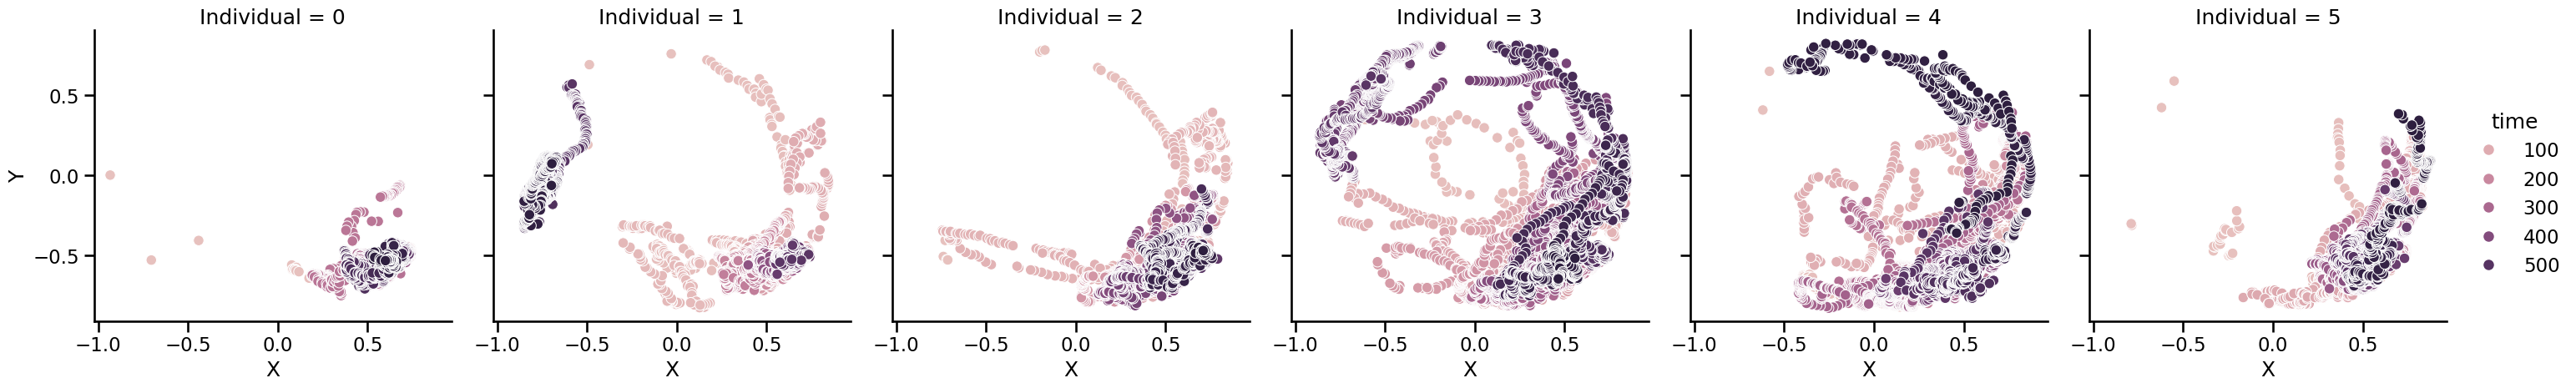

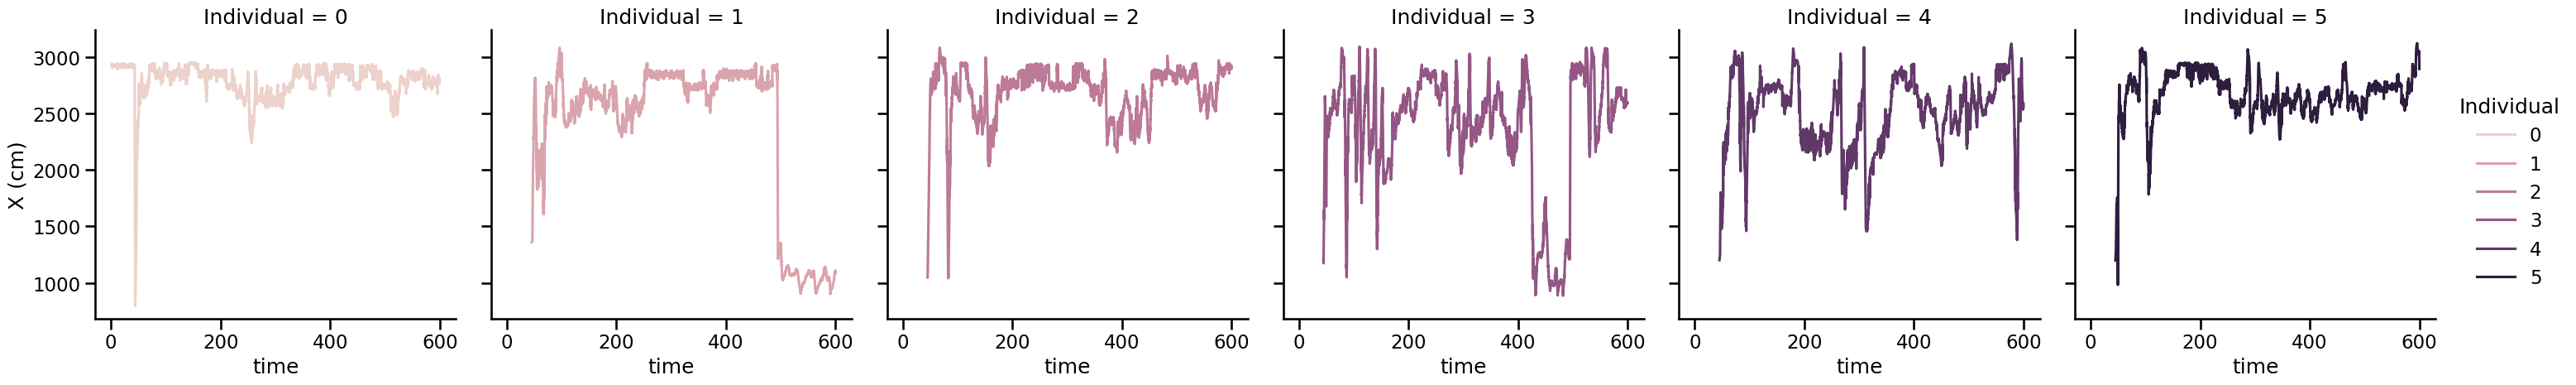

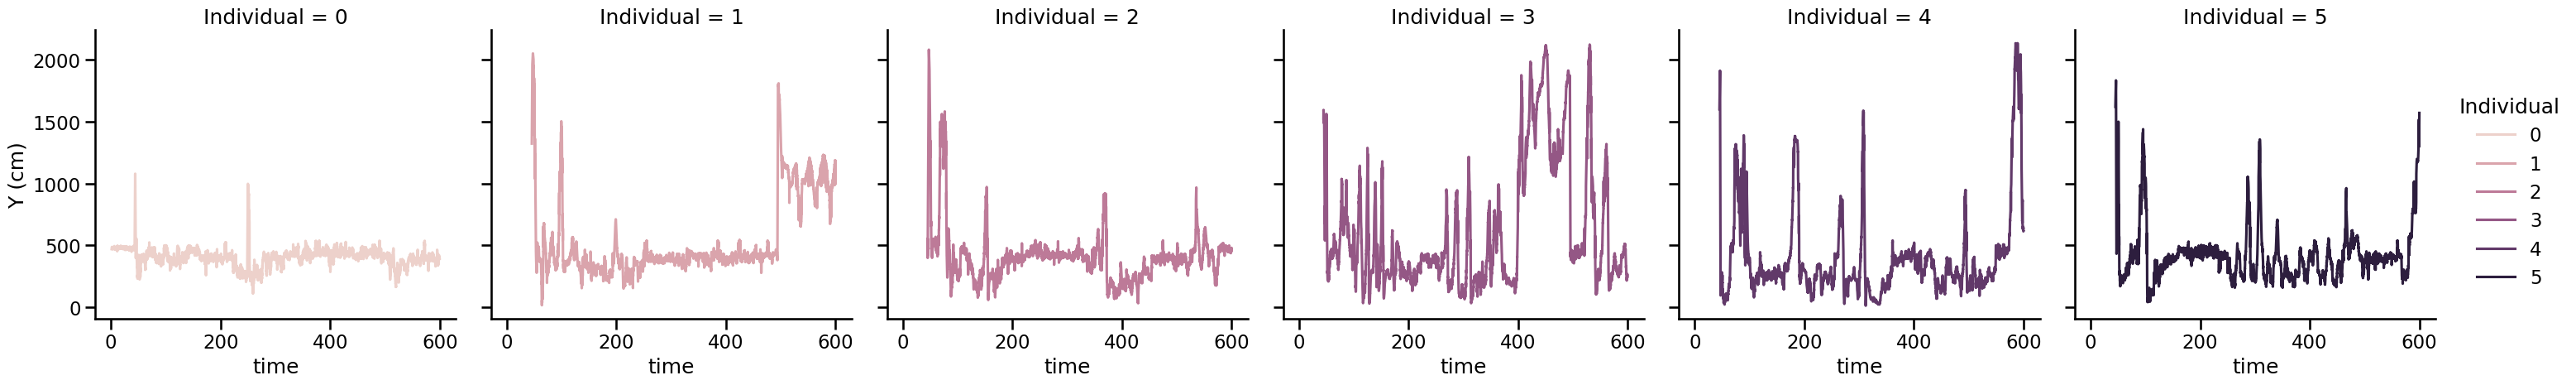

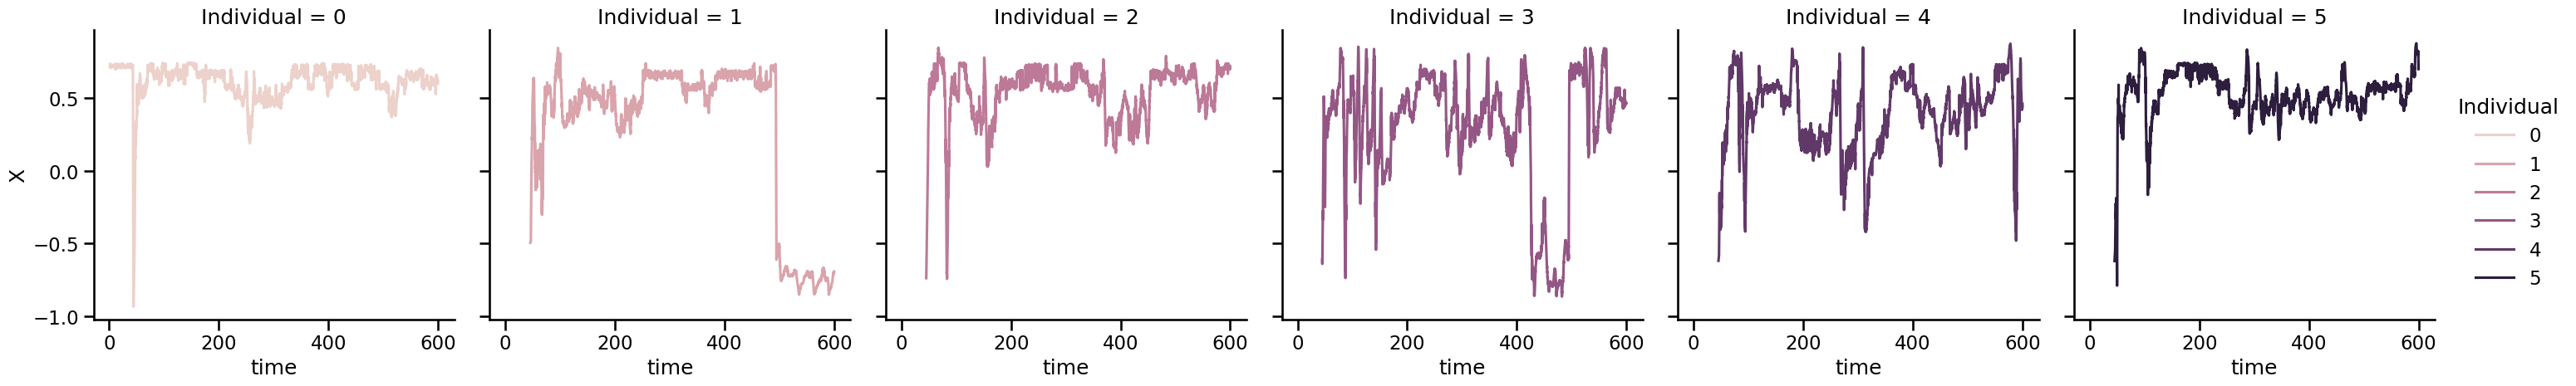

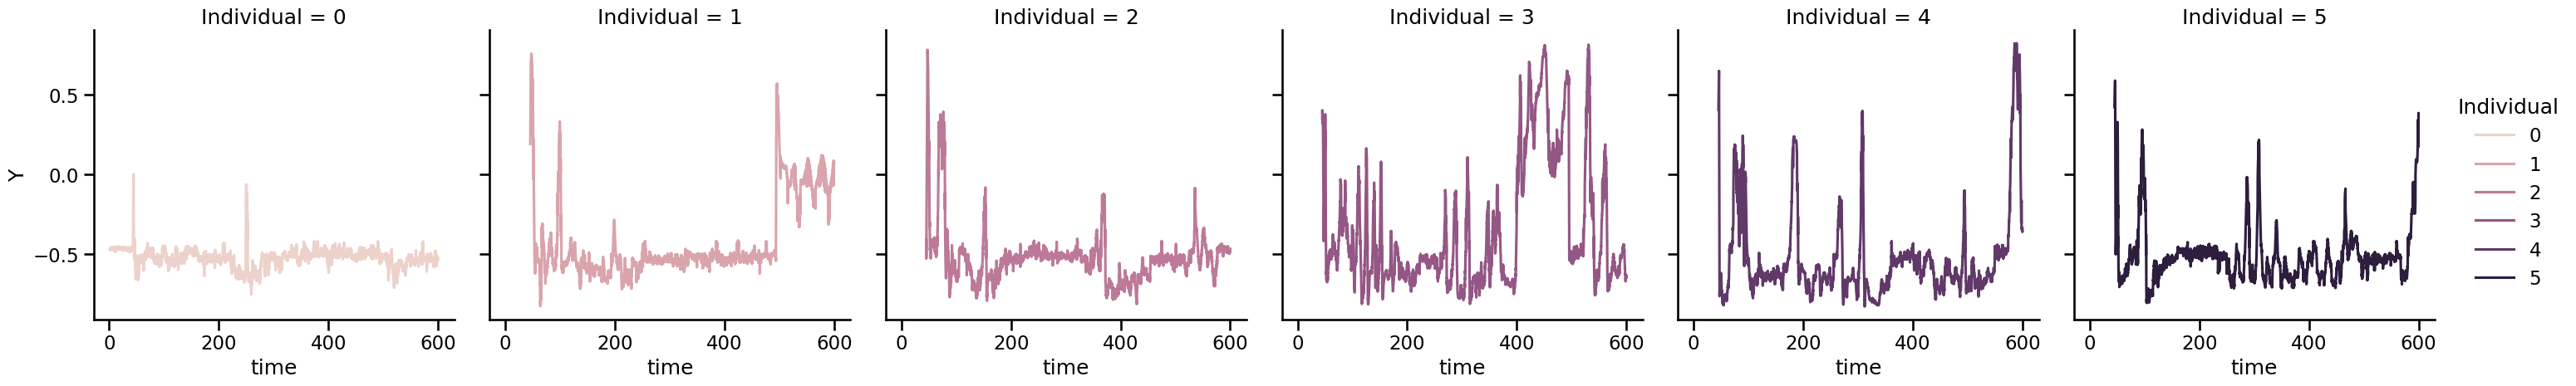

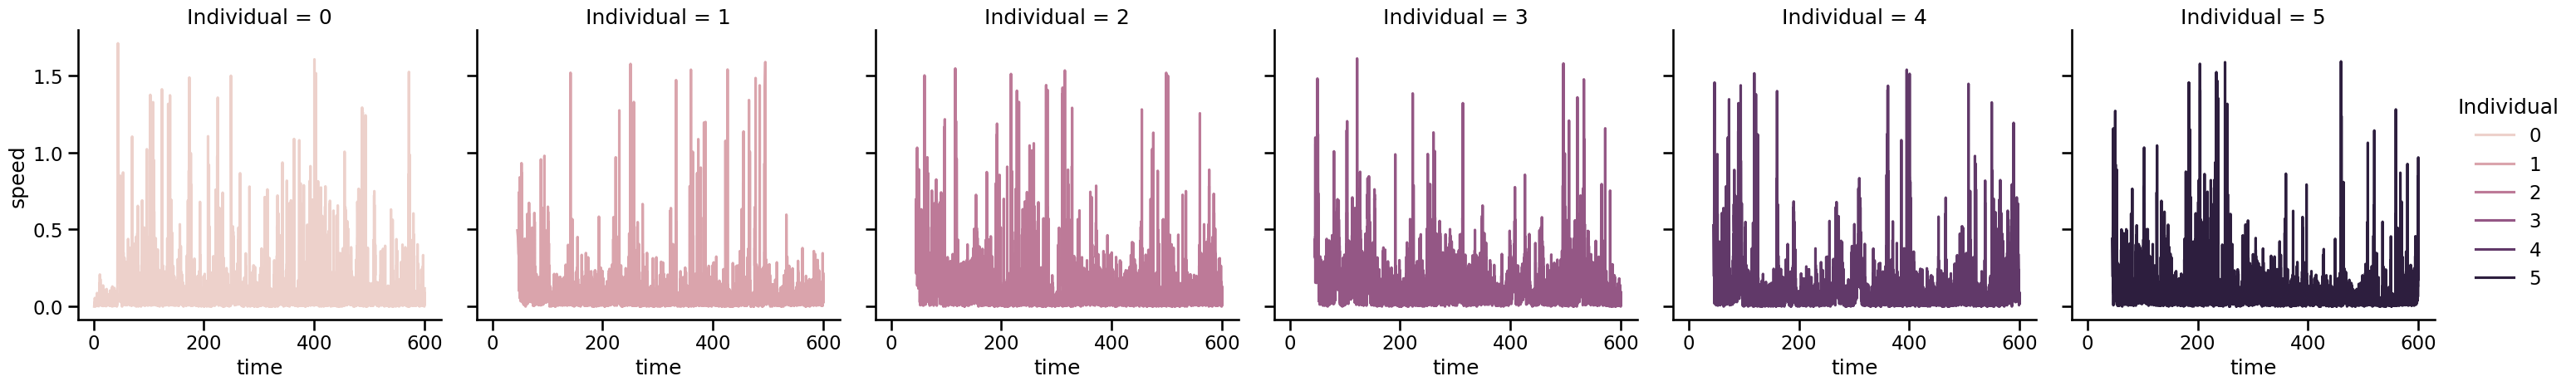

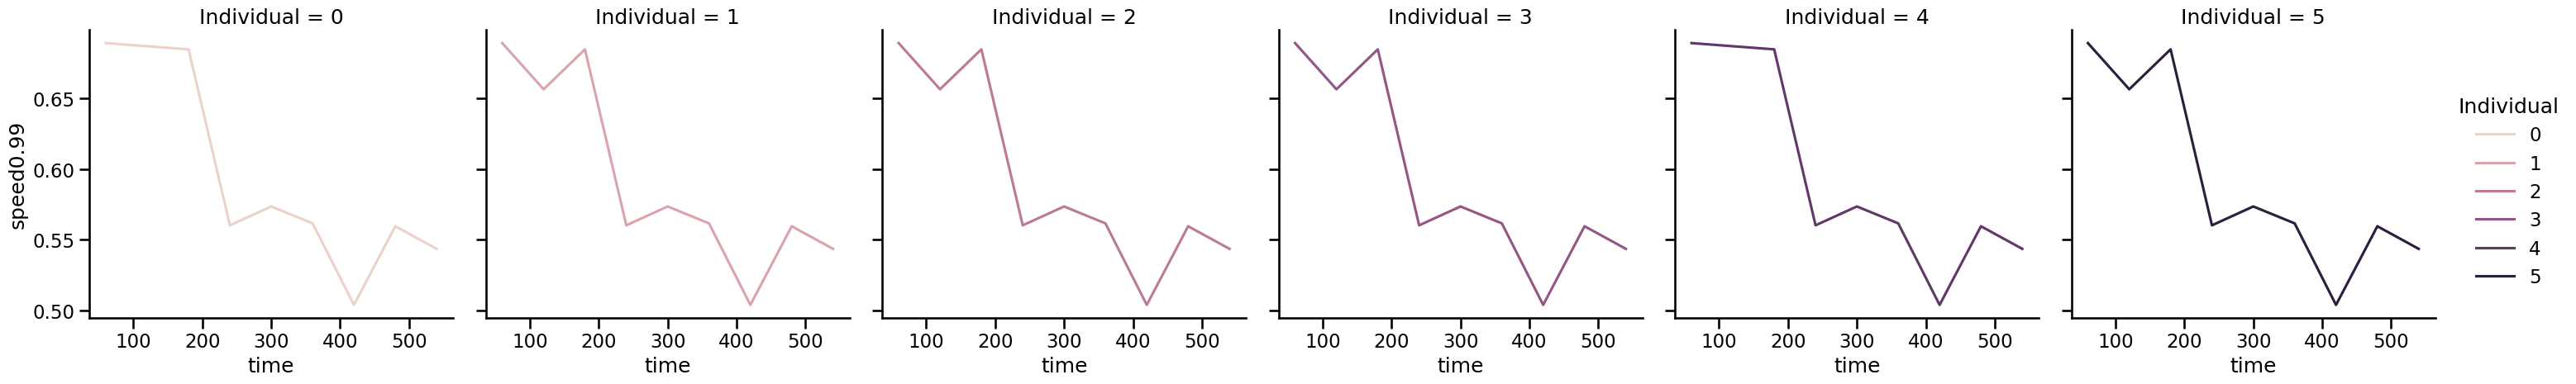

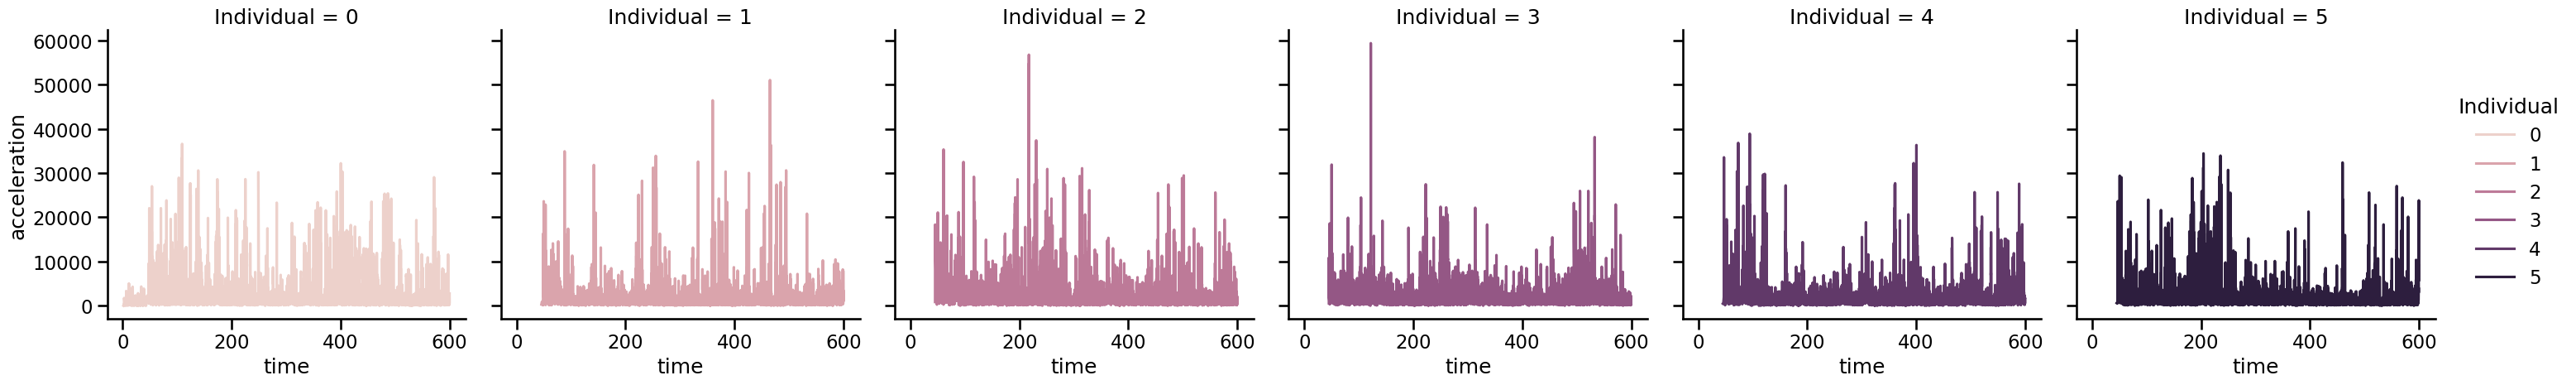

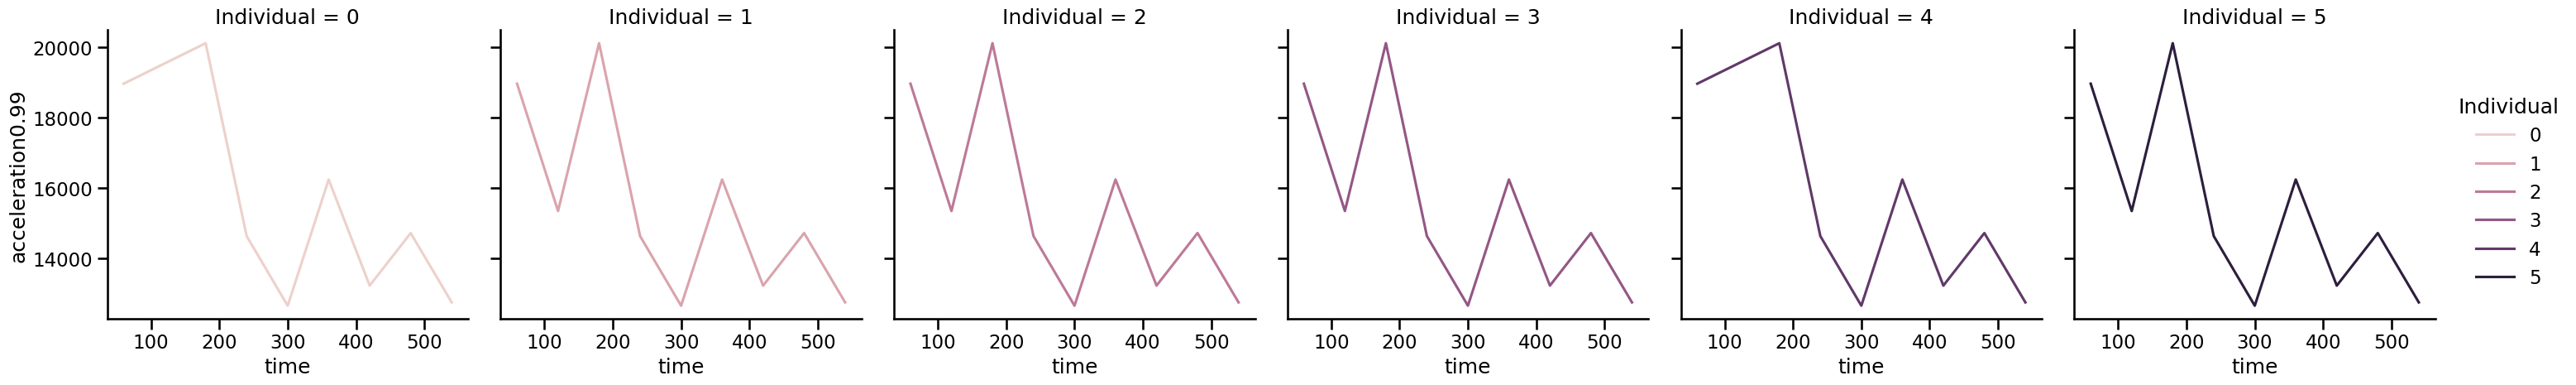

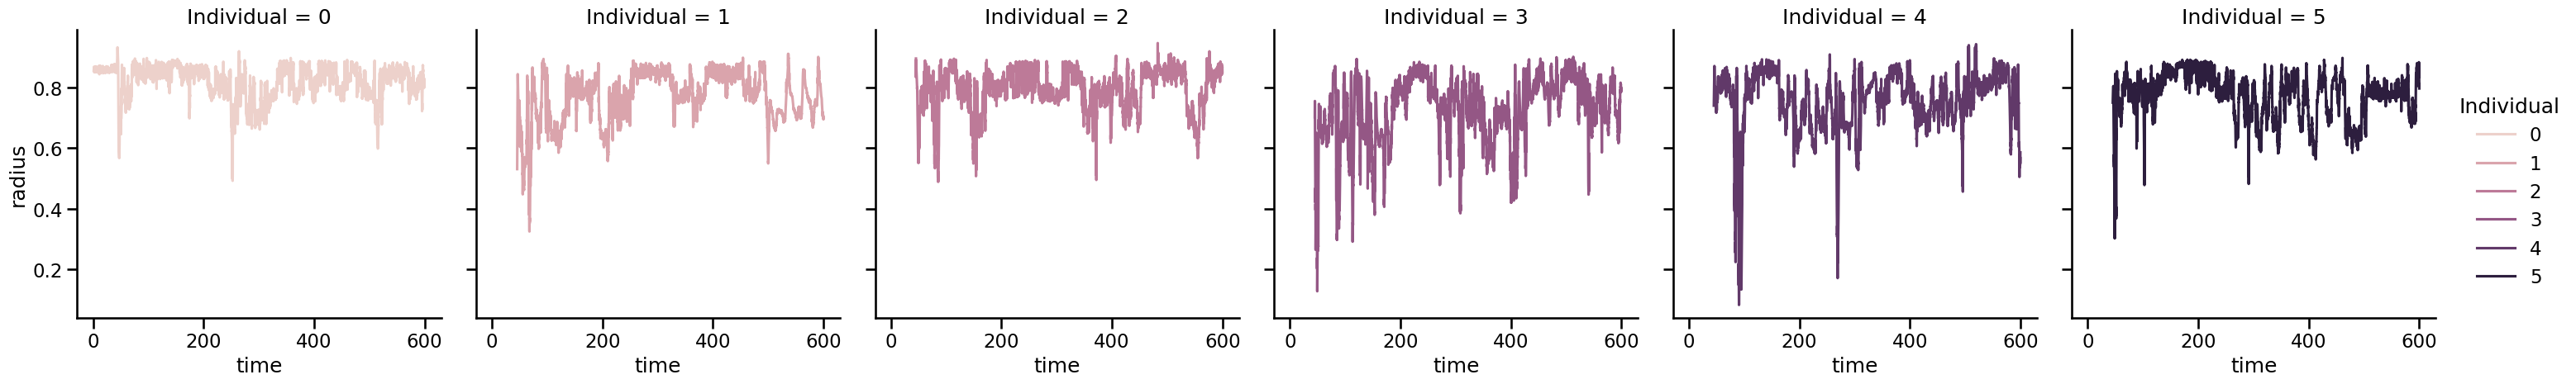

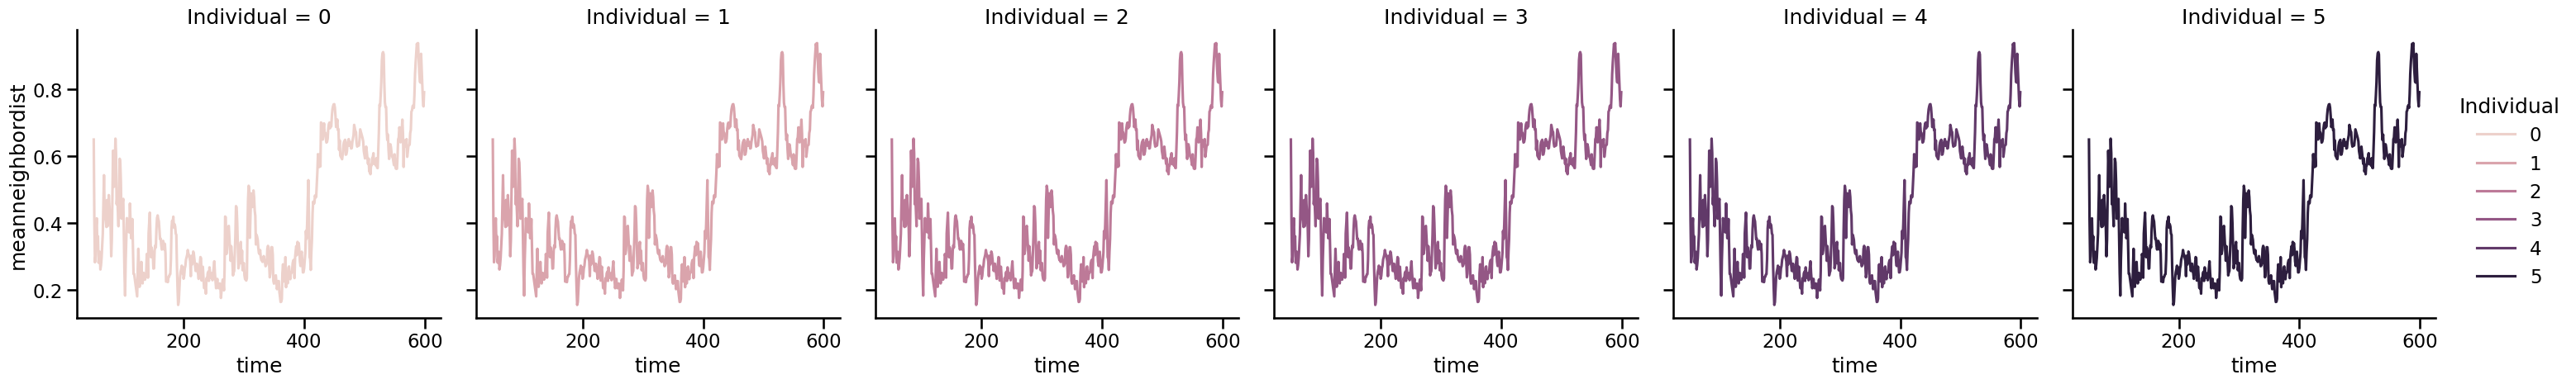

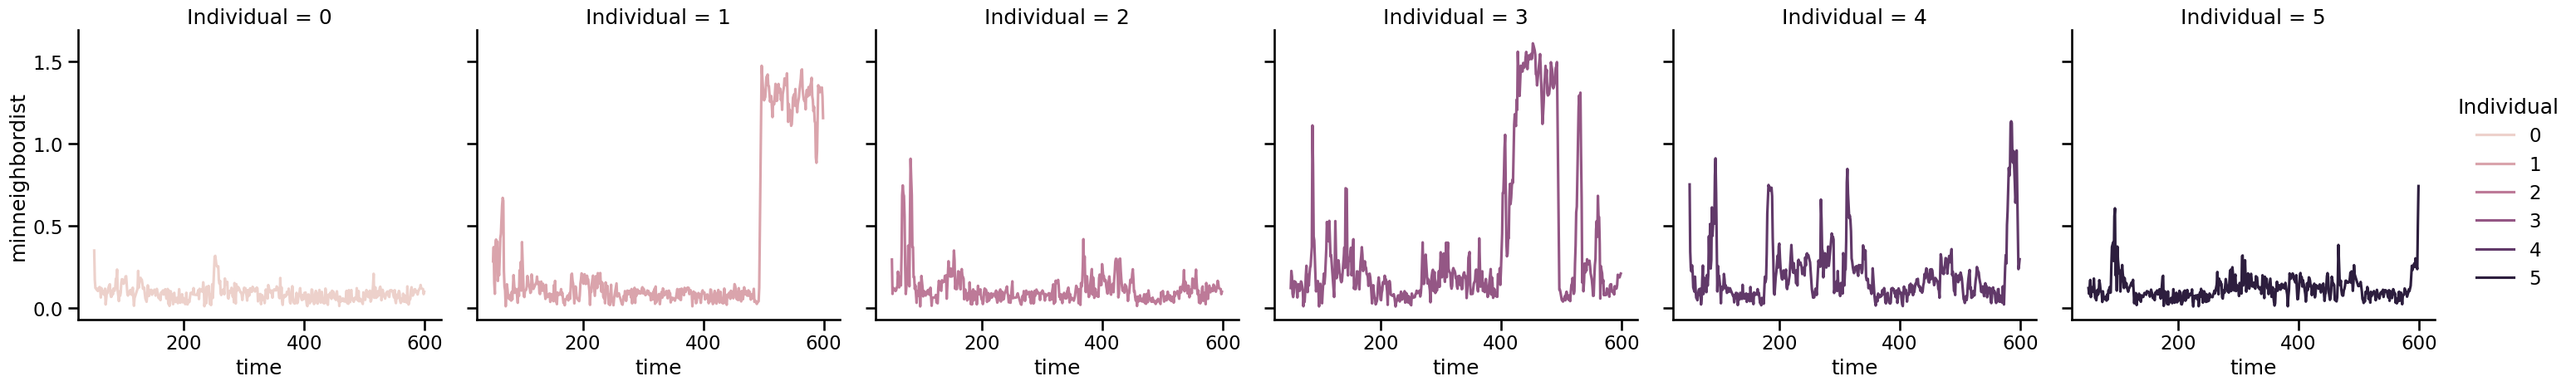

In [13]:
RIVER = "Skagit"
PH = 1
TRIAL = 8
VARIABLES = [
    "X (cm)",
    "Y (cm)",
    "X",
    "Y",
    "speed",
    "speed0.99",
    "acceleration",
    "acceleration0.99",
    "radius",
    "meanneighbordist",
    "minneighbordist",
]


one_video = df[
    (df["River"] == RIVER) &
    (df["pH"] == PH) &
    (df["Trial"] == TRIAL) &
    # (df["time"] > 0)
    (df["time"] < 60 * 10) &
    True
    ]

sns.relplot(data=one_video, x="X", y="Y", hue="time", col="Individual")

for var in VARIABLES:
    p = sns.relplot(data=one_video, x="time", y=var, kind="line", hue="Individual", col="Individual", errorbar=None)

# Set up intervals & variables

In [14]:
VARIABLES = [
    "speed",
    "acceleration",
    "speed0.99",
    "acceleration0.99",
    # "X (cm)",
    # "Y (cm)",
    "radius",
    "meanneighbordist",
    "minneighbordist",
]

# First 10 minutes
first_10 = df[
    (df["time"] > 60) &
    (df["time"] < 60 * 10)]

# 5 minutes before and after skin extract injection.
SKIN_EXTRACT_BEFORE = a, b = (-60 * 1, 0)
SKIN_EXTRACT_AFTER = c, d = (60 * 4, 60 * 5)
skin_extract_before = df[
    ((df["skin_extract_injection_time"] >= a) & (df["skin_extract_injection_time"] <= b))]
skin_extract_after = df[
     ((df["skin_extract_injection_time"] >= c) & (df["skin_extract_injection_time"] <= d))]

# visual disturbance.
VISUAL_DISTURBANCE_BEFORE = a, b = (-60 * 1, 0)
VISUAL_DISTURBANCE_AFTER_SHORT = c, d = (0, 2)
VISUAL_DISTURBANCE_AFTER_LONG = e, f = (2, 30)

visual_disturbance_before = df[
    (df["visual_disturbance_time"] >= a) & (df["visual_disturbance_time"] <= b)]
visual_disturbance_after_short = df[
     ((df["visual_disturbance_time"] >= c) & (df["visual_disturbance_time"] <= d))]
visual_disturbance_after_long = df[
     ((df["visual_disturbance_time"] >= e) & (df["visual_disturbance_time"] <= f))]


# Step 1. Qualitative analysis.

- One for each variable of interest (speed, mean distance btw. neighbors, radial pos)
- look at 3 different time series
- relaxation at the start (0 - ?)
- time series around the alarm (-? - +?)
- time series around the startle event (-? - +?)
- 6 different curves. average these. one for each Ph.
- or two panels.


ValueError: cannot reindex on an axis with duplicate labels

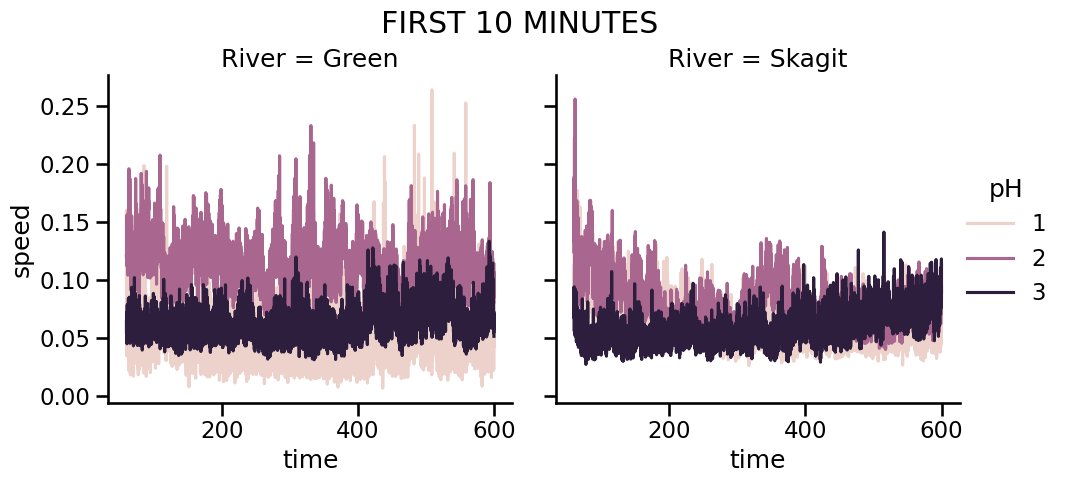

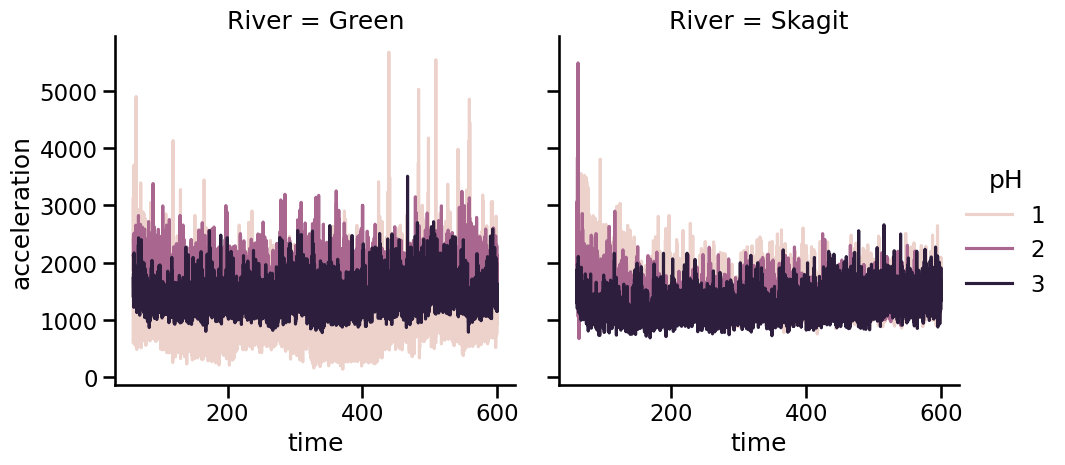

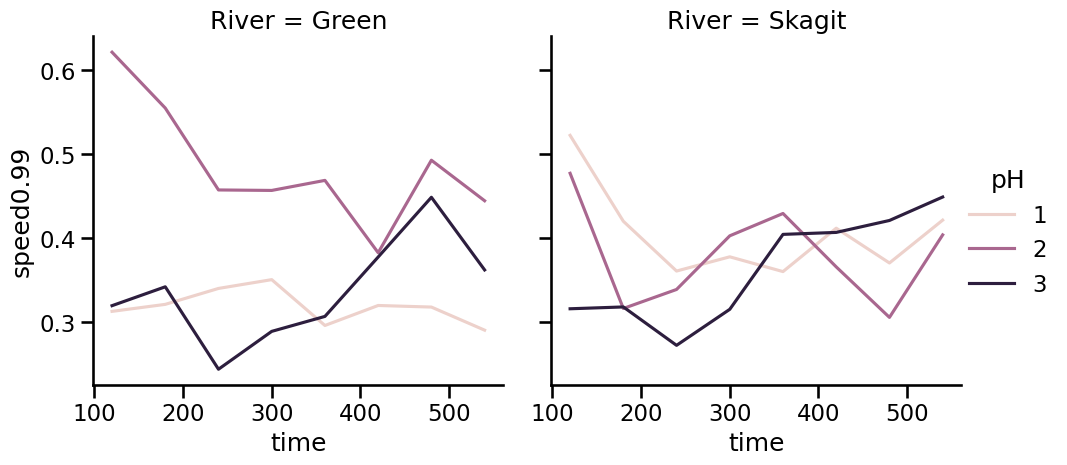

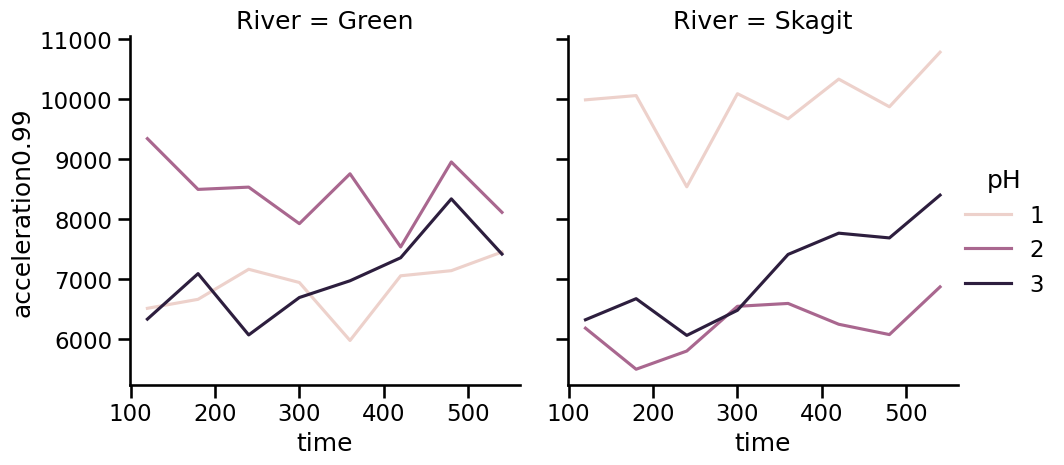

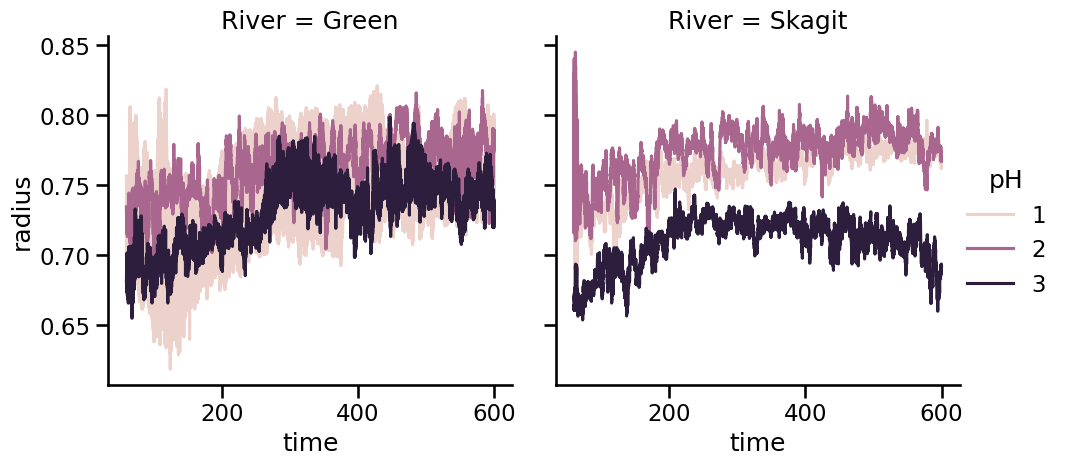

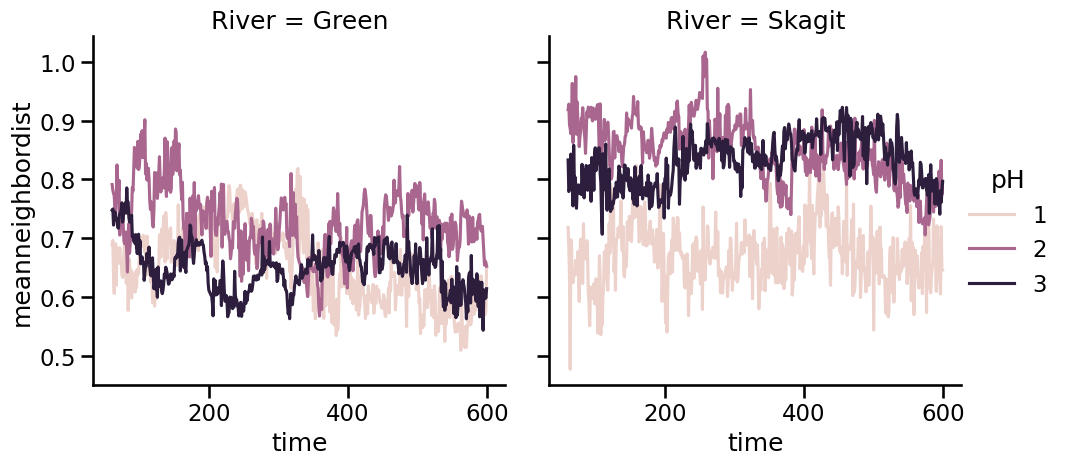

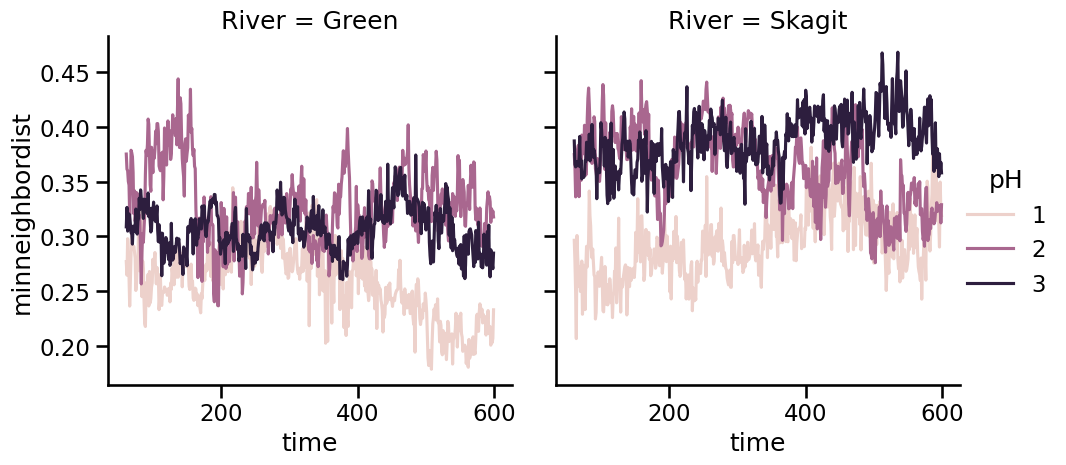

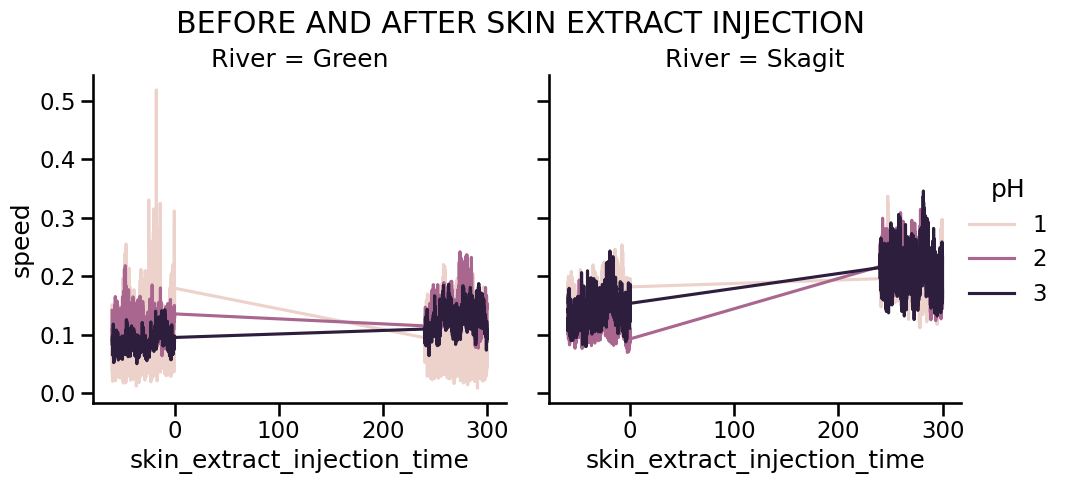

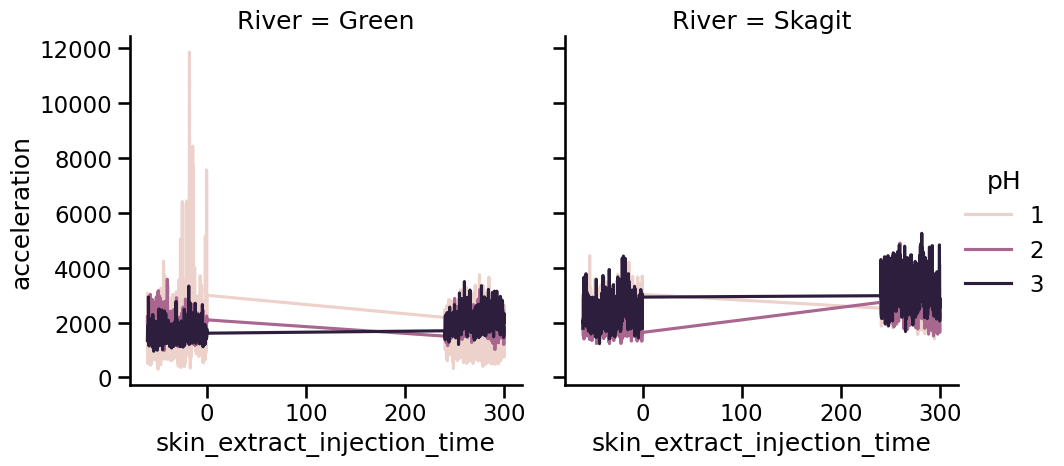

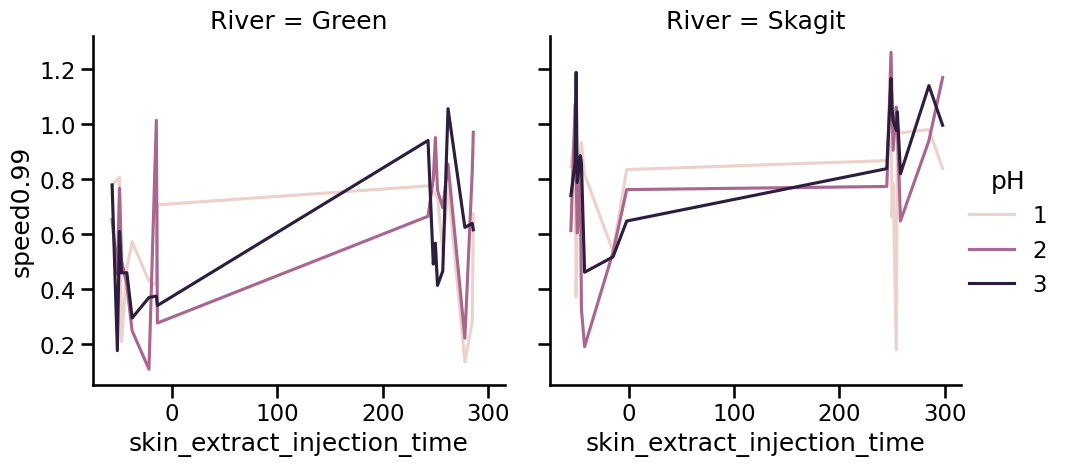

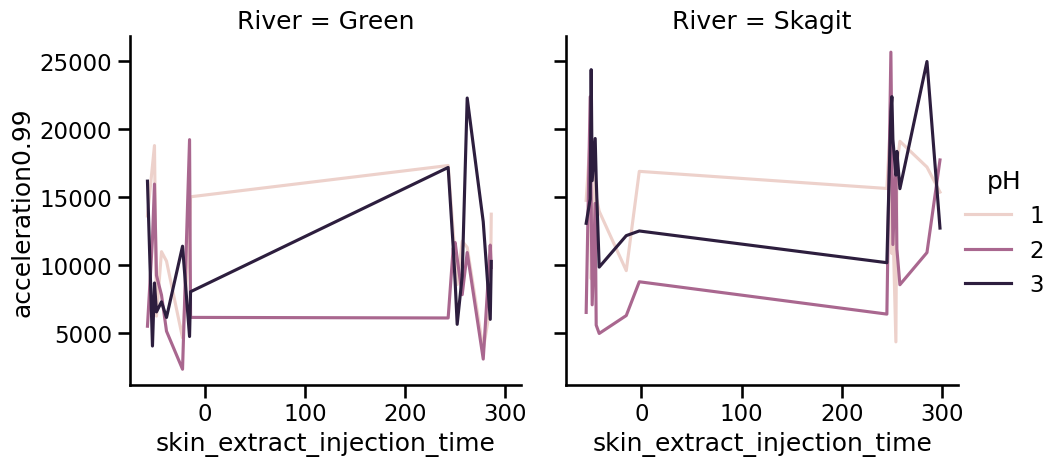

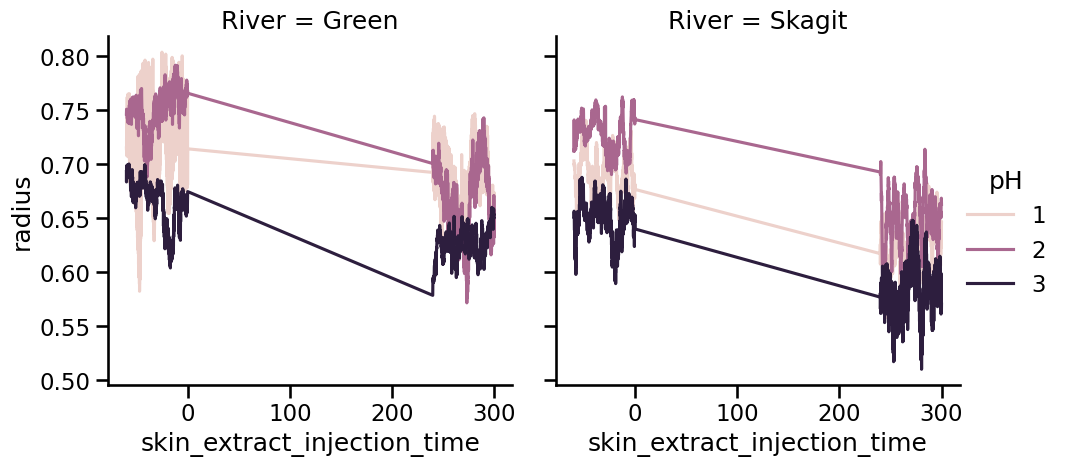

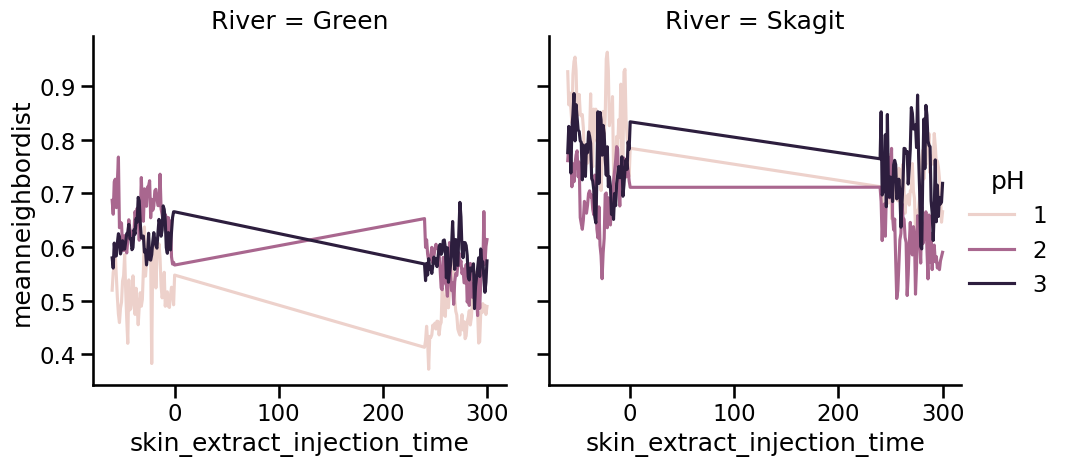

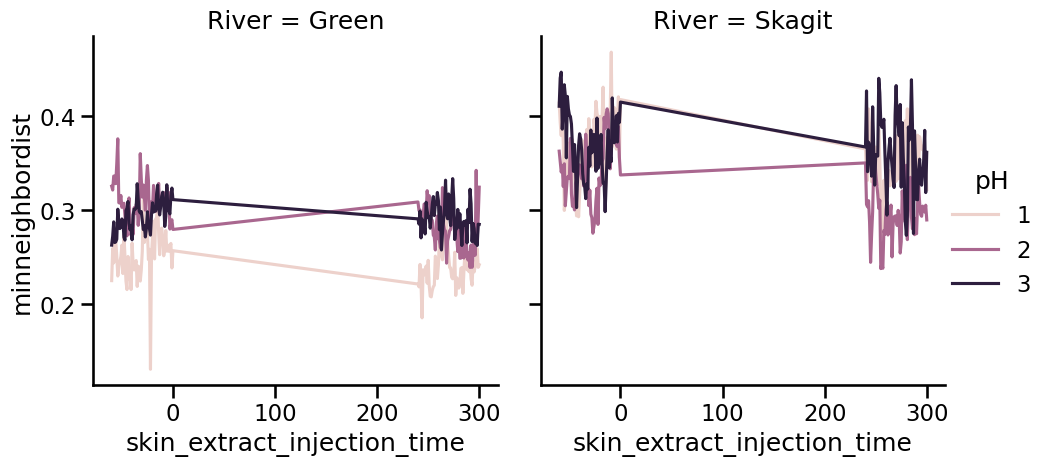

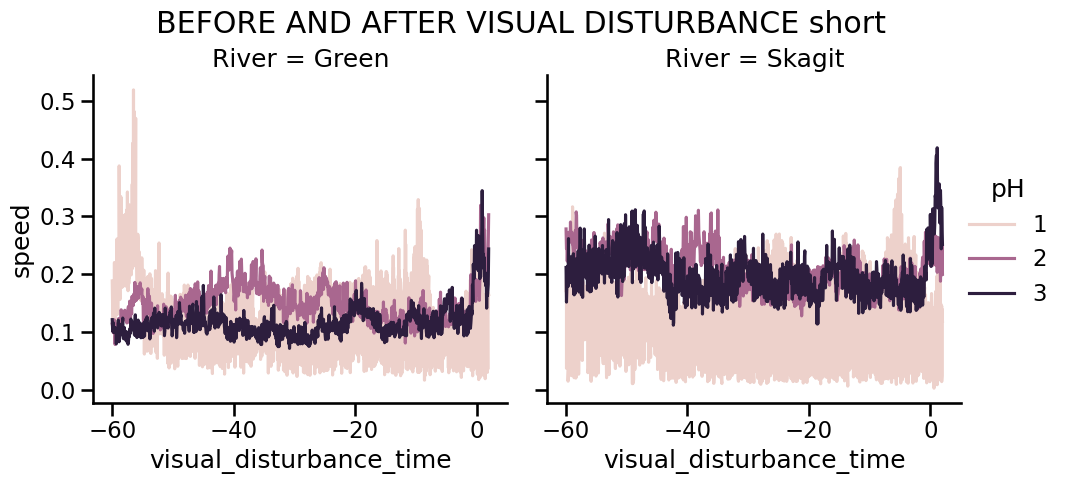

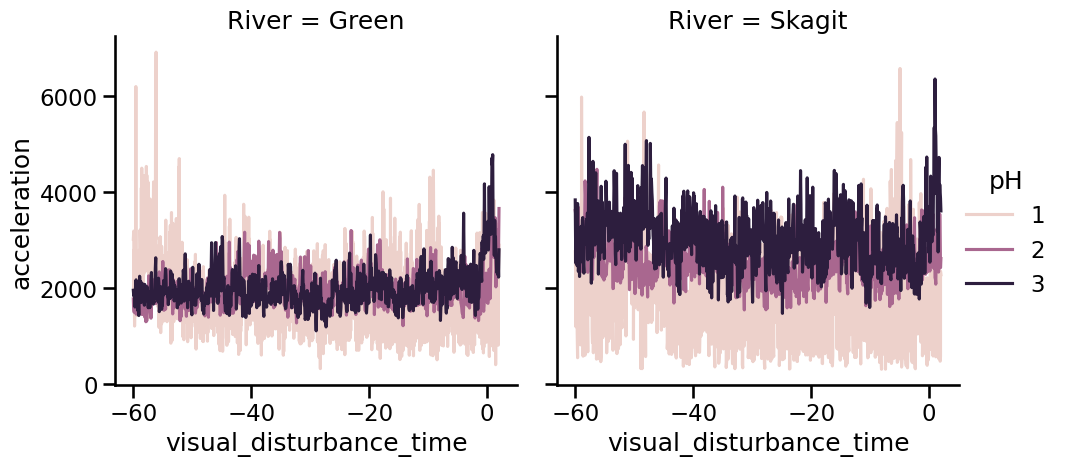

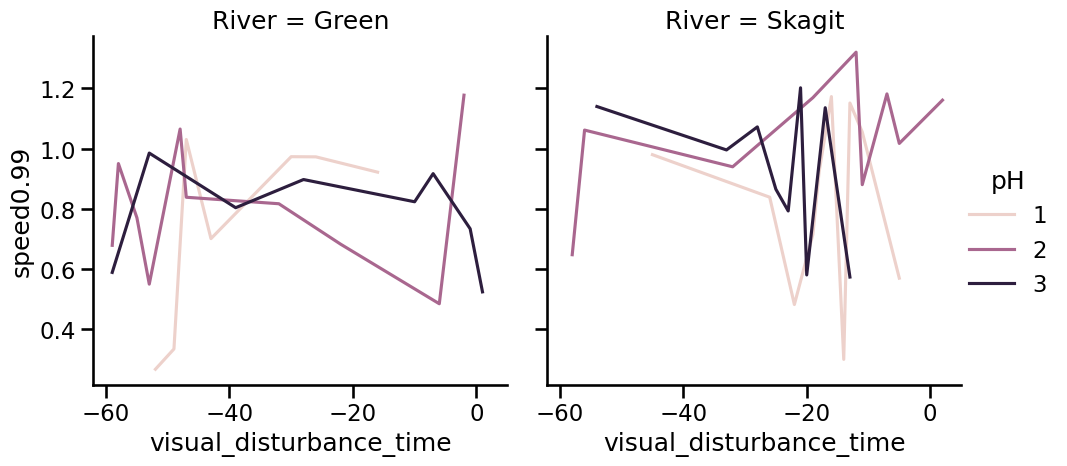

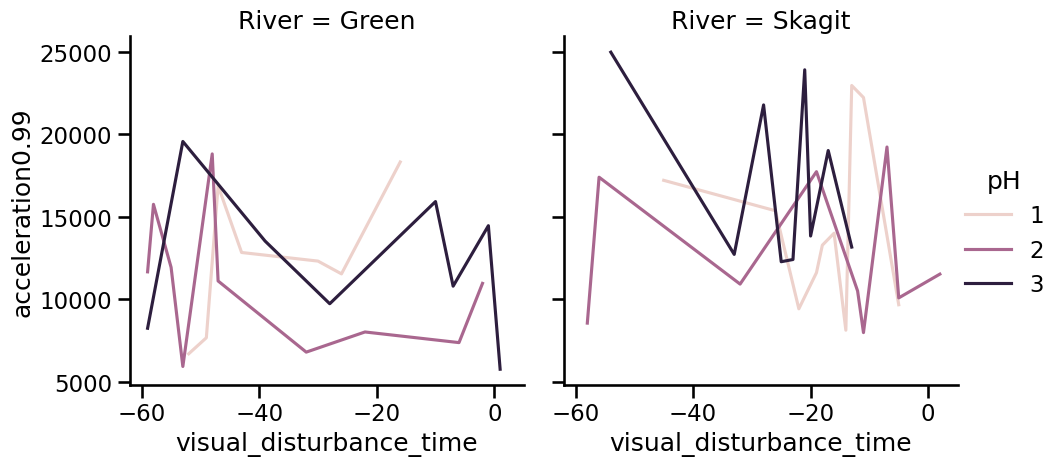

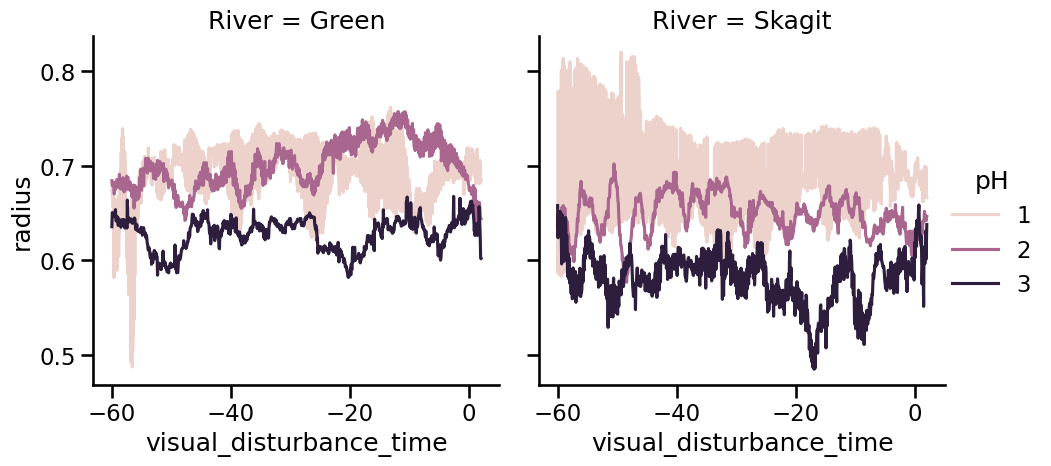

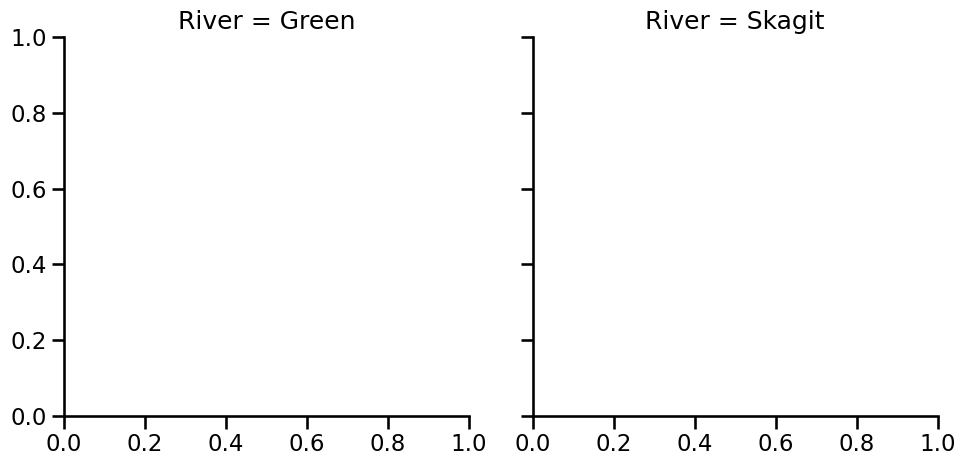

In [15]:
for _df, title, time_var in [
    (first_10, "FIRST 10 MINUTES", "time"),
    (pd.concat([skin_extract_before, skin_extract_after]),
         "BEFORE AND AFTER SKIN EXTRACT INJECTION",  "skin_extract_injection_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_short]),
         "BEFORE AND AFTER VISUAL DISTURBANCE short", "visual_disturbance_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_long]),
     "BEFORE AND AFTER VISUAL DISTURBANCE long", "visual_disturbance_time"),
]:


    for i, var in enumerate(VARIABLES):
        p = sns.relplot(data=_df, x=time_var, y=var, kind="line", col="River", hue="pH", errorbar=None)
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)


# Step 2. Histogram of variables (speed, mean distance btw neighbors, radial pos)

- first 5 minutes
- 10 minutes leading up to the pheromone
- 3 minutes after the pheromone
- 30 seconds after the startle



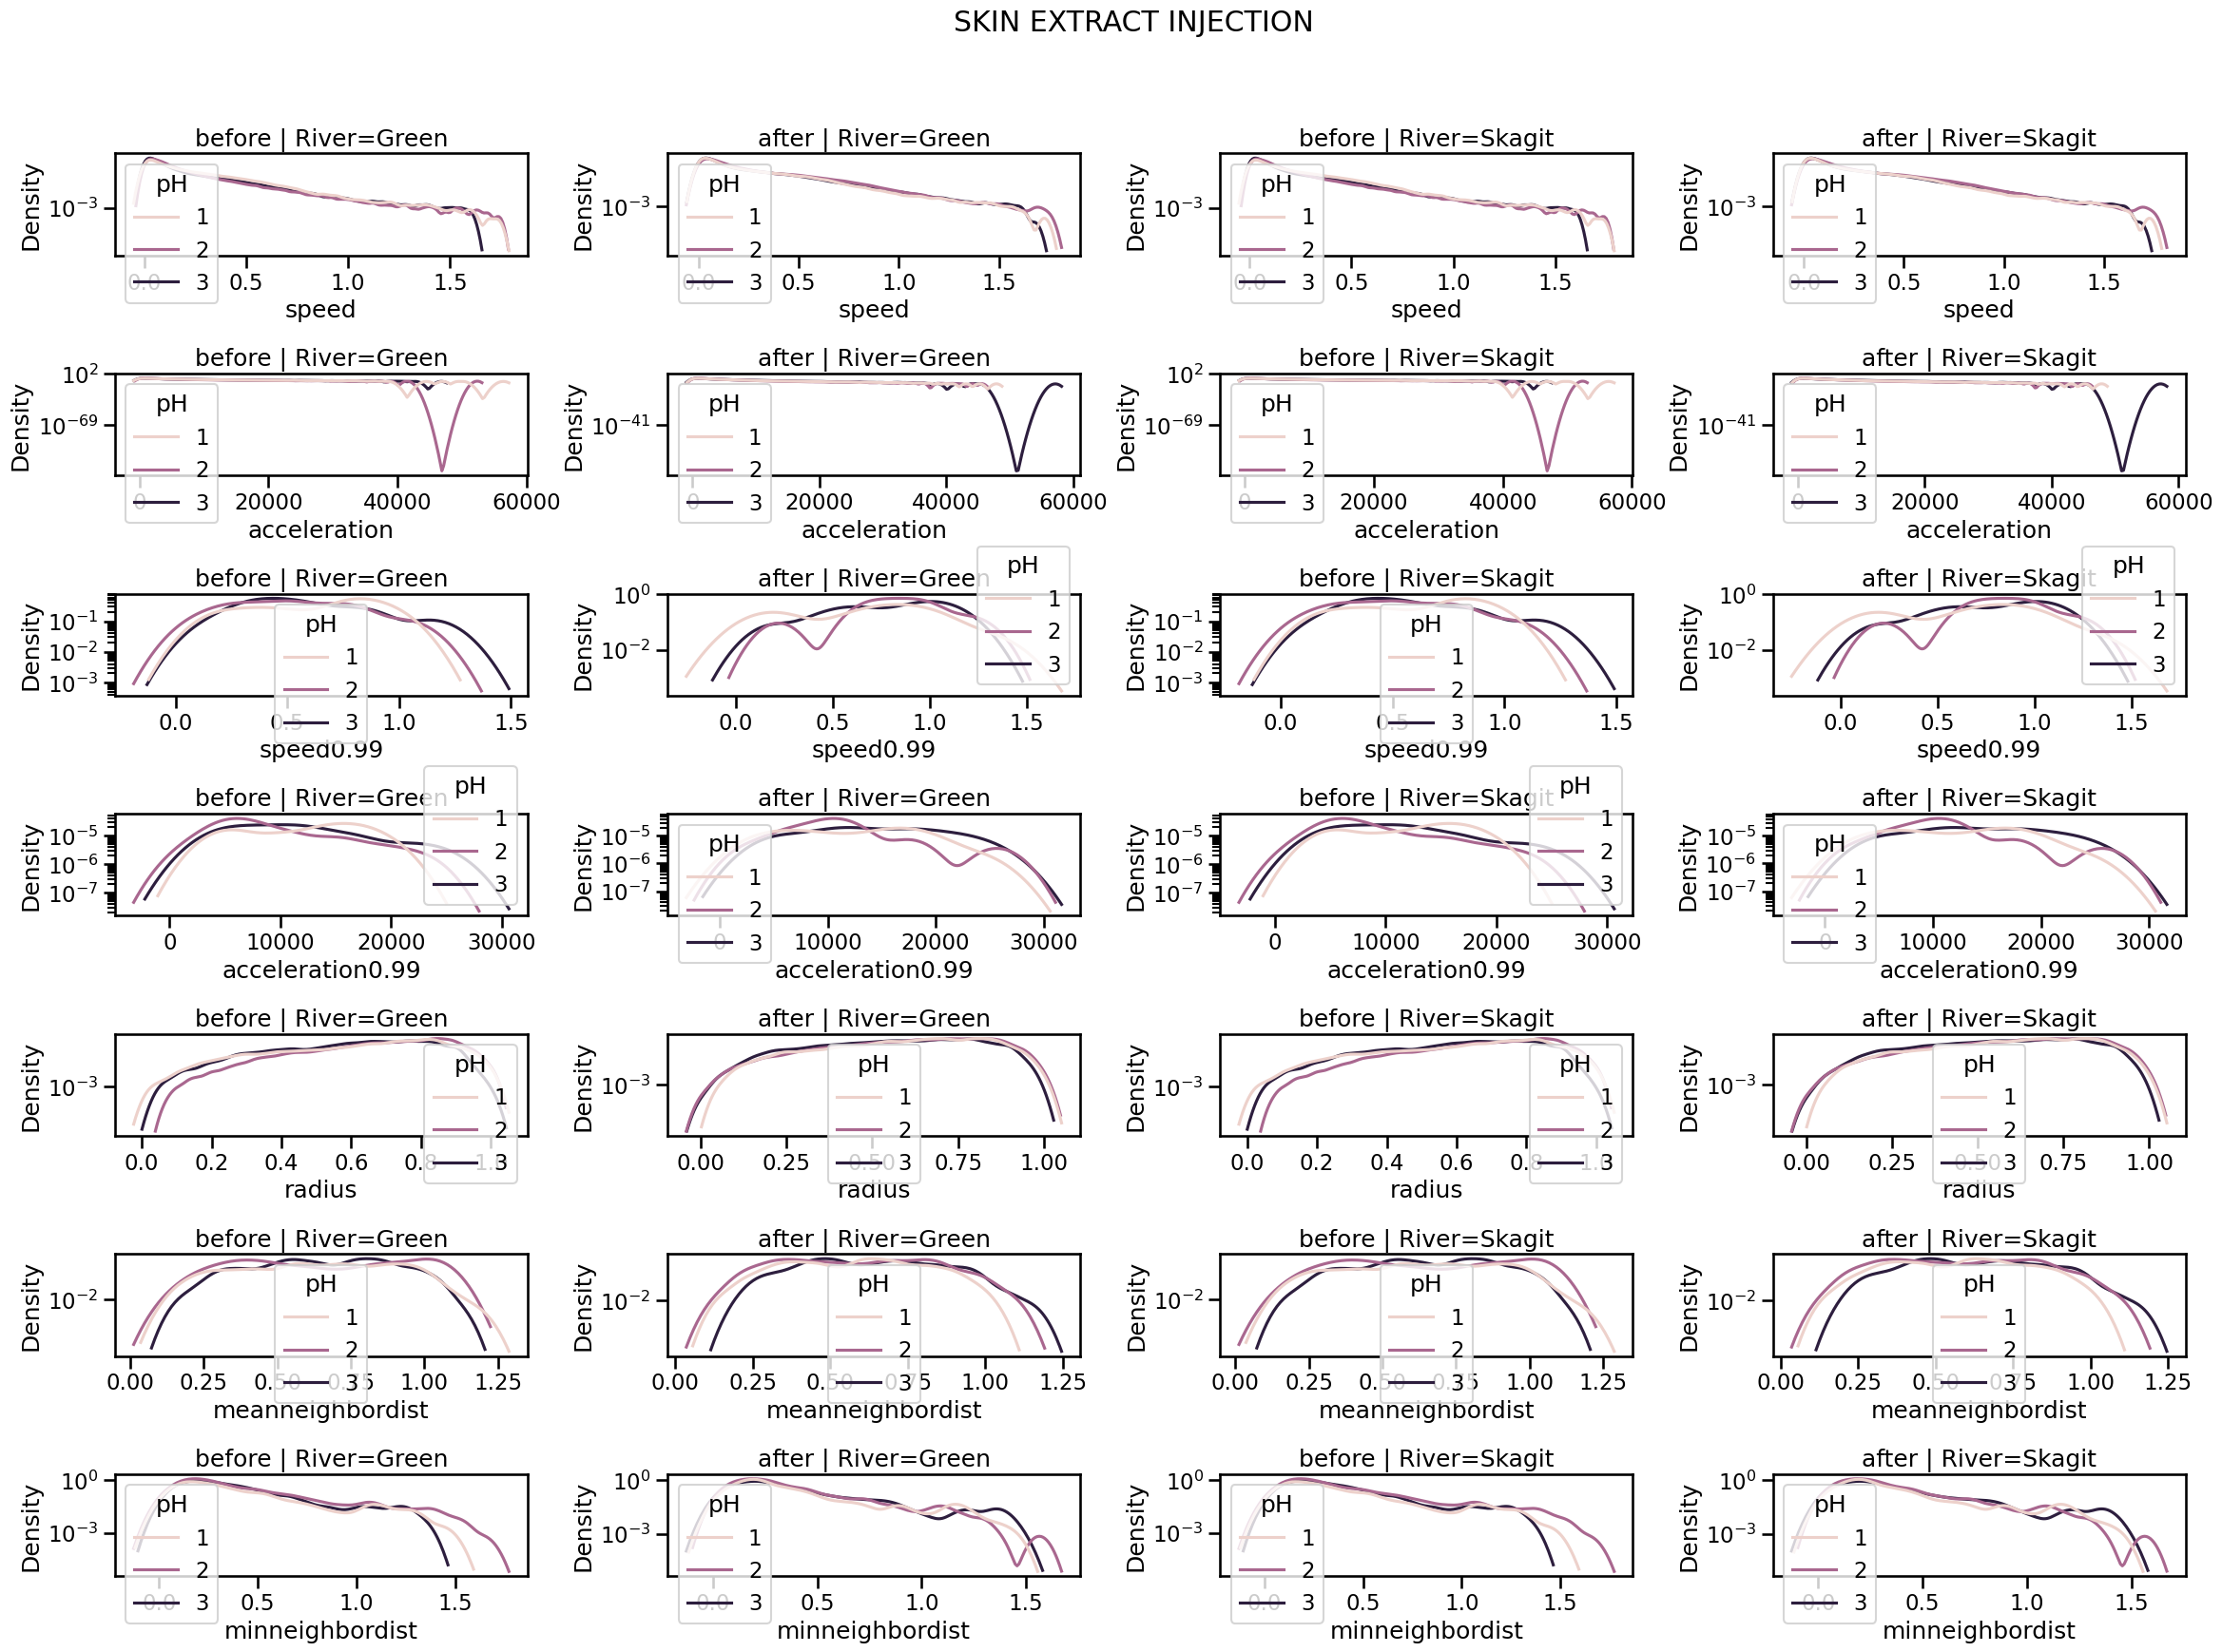

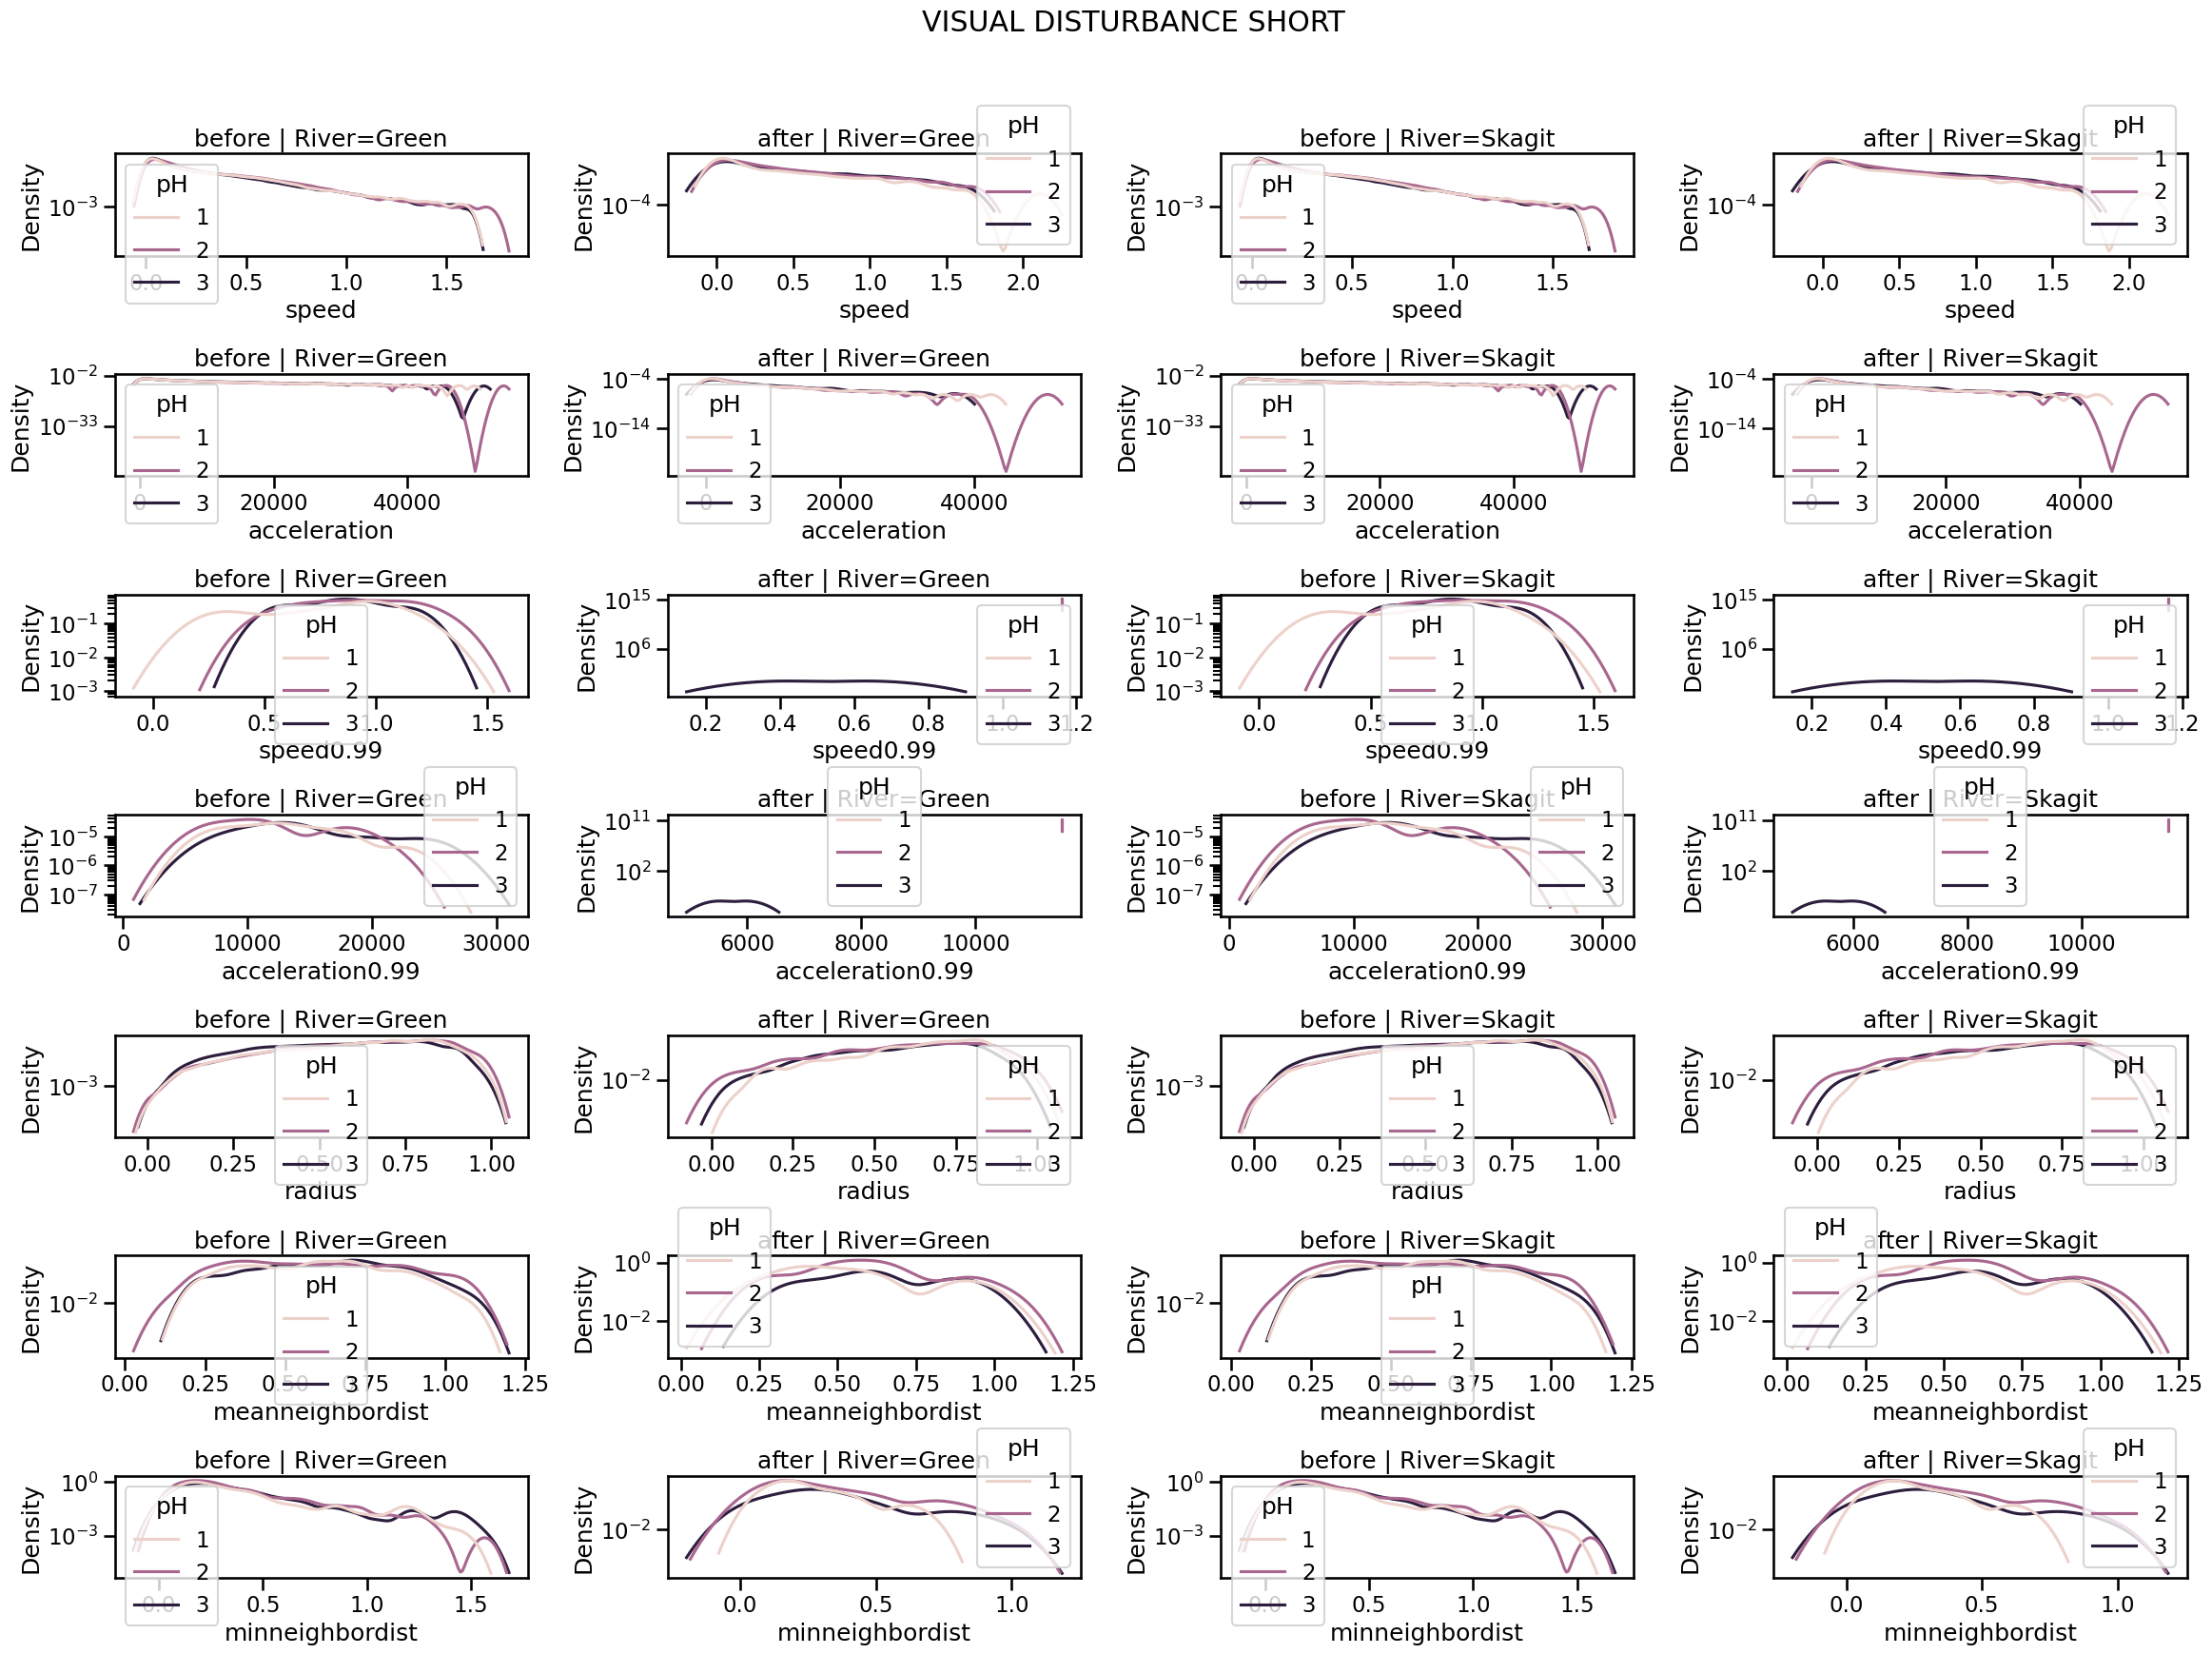

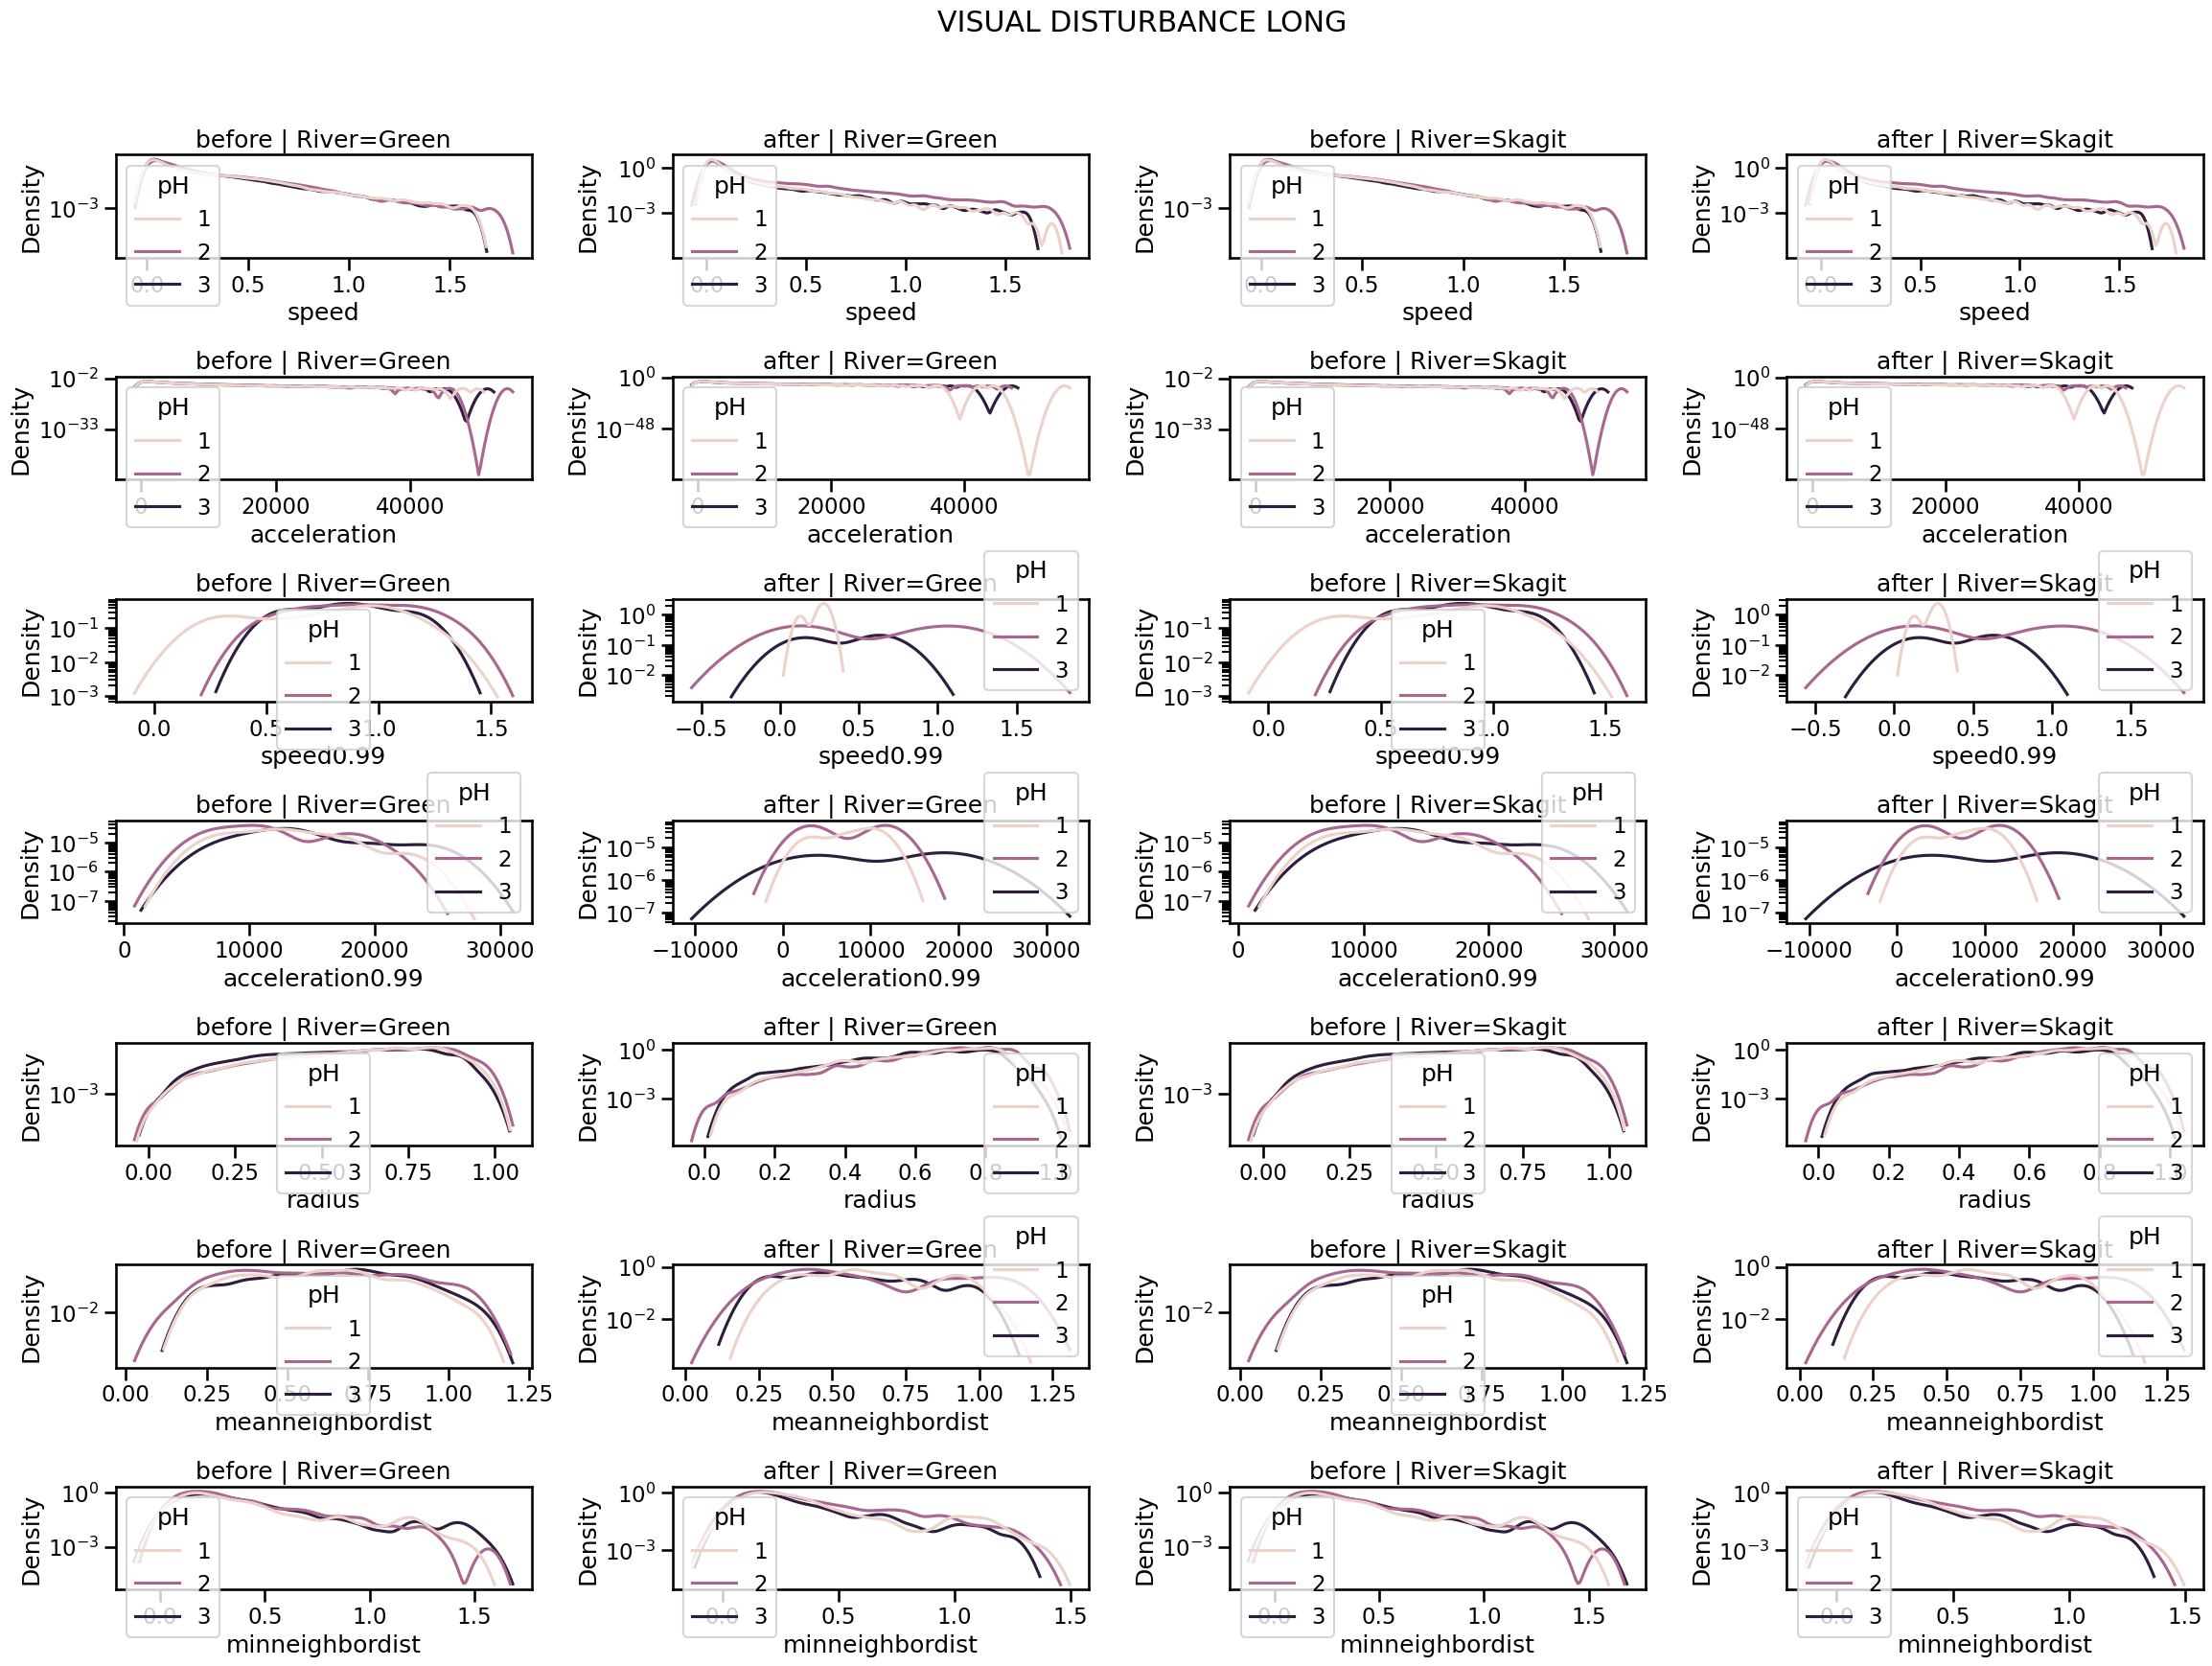

In [16]:
# before on the left, after on the right? 

PLOT_FUNC = sns.kdeplot
# PLOT_FUNC = sns.histplot
LOG_Y = True

for before, after, title in [
    # (first_10, "FIRST 10 MINUTES"),
    (skin_extract_before, skin_extract_after, "SKIN EXTRACT INJECTION"),
    (visual_disturbance_before, visual_disturbance_after_short, "VISUAL DISTURBANCE SHORT"),
    (visual_disturbance_before, visual_disturbance_after_long, "VISUAL DISTURBANCE LONG")
]:
    
    
    # for i, var in enumerate(VARIABLES):
        
    fig, axes = plt.subplots(nrows=len(VARIABLES), ncols=4, figsize=(24, 18))
    fig.suptitle(title)
    plt.tight_layout(pad=3.0)

    for i, var in enumerate(VARIABLES):
        for j, river in enumerate(["Green", "Skagit"]):
            # axs[i, 2 * j]
            
            b = PLOT_FUNC(
                data=before, x=var,
                hue="pH",
                # multiple="dodge",
                # stat="probability",
                # bins=10,
                ax=axes[i, 2*j],
                # (x_scale, y_scale)
                # log_scale=(False, True),
            )
            b.set(title=f"before | River={river}")
            
            a = PLOT_FUNC(
                data=after, x=var,
                hue="pH",
                # multiple="dodge",
                # stat="probability",
                # bins=10,
                ax=axes[i, 2*j + 1],
                # (x_scale, y_scale)
                # log_scale=(False, True),
            )
            a.set(title=f"after | River={river}")

            if LOG_Y:
                a.set(yscale='log')
                b.set(yscale='log')
                

            # # p.set(yscale='log')
            # if i == 0:
            #     p.fig.suptitle(title) # can still add, e.g., fontsize=16
            #     p.fig.subplots_adjust(top=0.85)



# Step 3. Some sort of difference around the pheromone introduction & around the startle

- delta of the histograms between before & after timing
- one for pheromones, one for the startle
- or a histogram of the deltas of the means.
- some way to quantify how the distribution is changing.


In [17]:
# Computes these intervals for before/after skin_extract time
data = []
# Groups by trial: all fish go into the mean.
GROUPBY_VARS = ["River", "pH", "Trial"]
DELTA_VARS = [
    "speed",
    "acceleration", 
    "speed0.99",
    "acceleration0.99",
    "radius",
    "meanneighbordist",
    "minneighbordist"
]


def compute_deltas(df, col_name, INTERVALS):
    a, b, c, d = INTERVALS
    for group_name, group_df in df.groupby(GROUPBY_VARS):
        before_df = group_df[
            (group_df[col_name] >= a) &
            (group_df[col_name] <= b)]
        after_df = group_df[
            (group_df[col_name] >= c) &
            (group_df[col_name] <= d)]
    
        # This is all the column values as a list.
        row = list(group_name)
    
        for delta_var in DELTA_VARS:
            delta = after_df[delta_var].replace([np.inf, -np.inf], np.nan).mean() - before_df[delta_var].replace([np.inf, -np.inf], np.nan).mean()
            row.append(delta)
            
    
        data.append(row)
    
    deltas_df = pd.DataFrame(data, columns=GROUPBY_VARS + [delta_var + "_delta" for delta_var in DELTA_VARS])
    return deltas_df

# These are just hard-coded to match the intervals from above.
a, b, c, d = SKIN_EXTRACT_BEFORE + SKIN_EXTRACT_AFTER
skin_extract_deltas = compute_deltas(df, "skin_extract_injection_time", SKIN_EXTRACT_BEFORE + SKIN_EXTRACT_AFTER)

visual_disturbance_short_deltas = compute_deltas(df, "visual_disturbance_time", VISUAL_DISTURBANCE_BEFORE + VISUAL_DISTURBANCE_AFTER_SHORT)
visual_disturbance_long_deltas = compute_deltas(df, "visual_disturbance_time", VISUAL_DISTURBANCE_BEFORE + VISUAL_DISTURBANCE_AFTER_LONG)

/Users/brendan/Library/Python/3.9/lib/python/site-packages/seaborn/axisgrid.py:453: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=figsize)


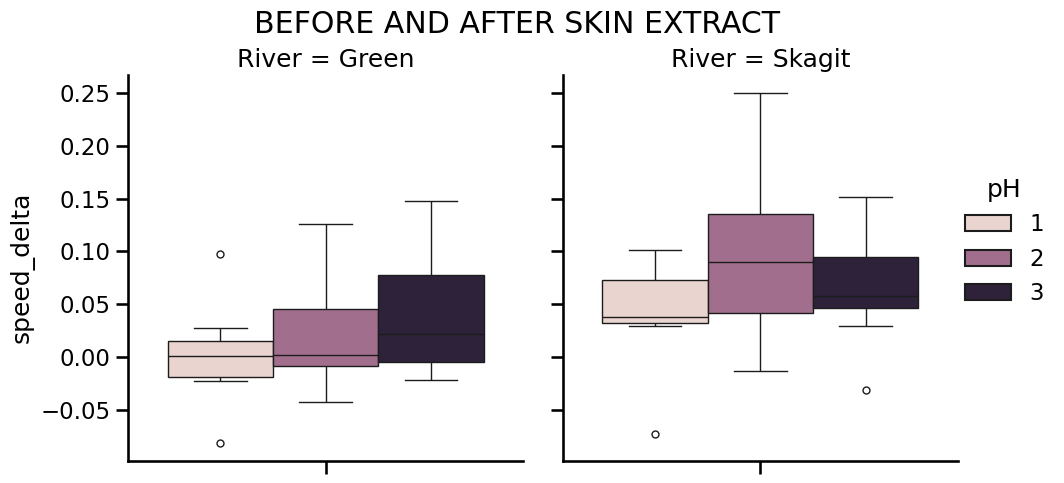

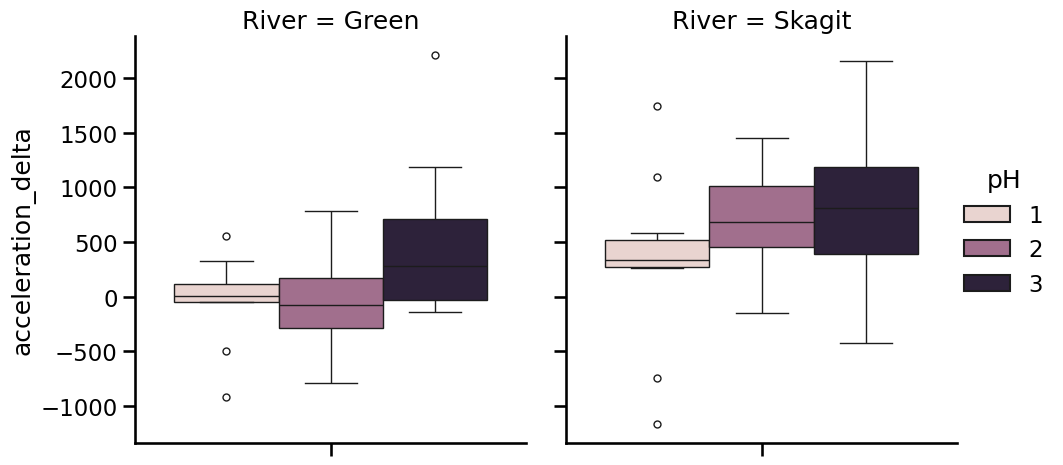

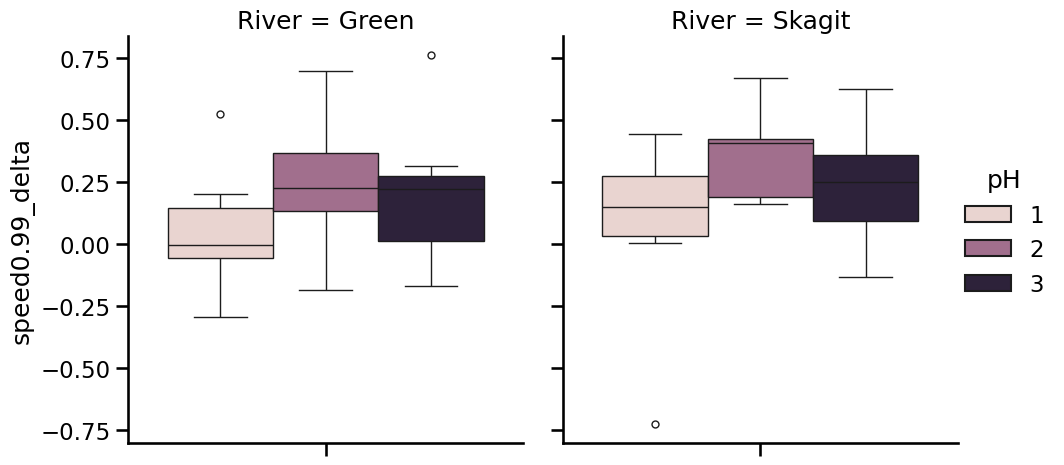

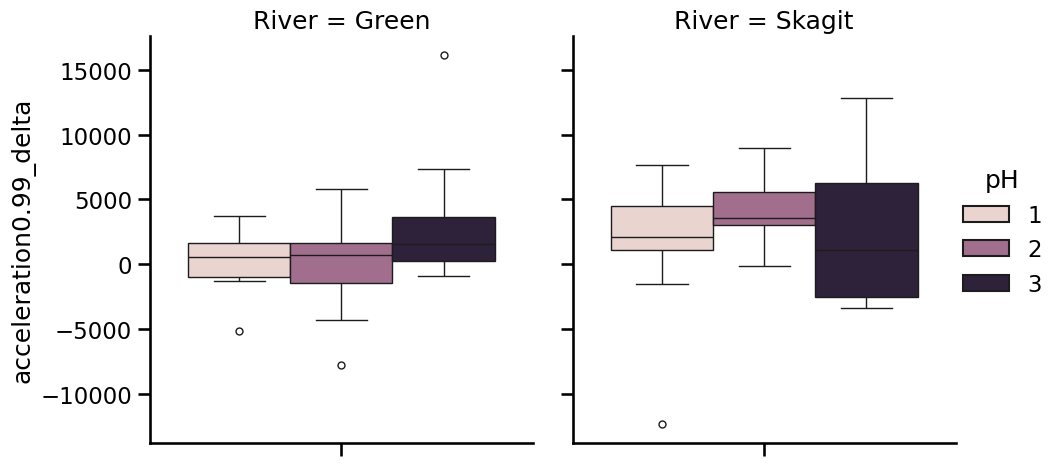

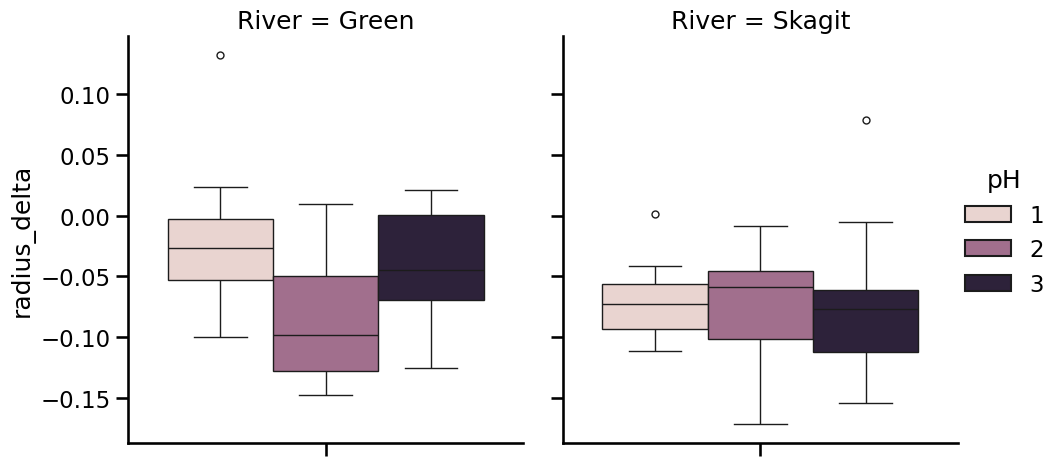

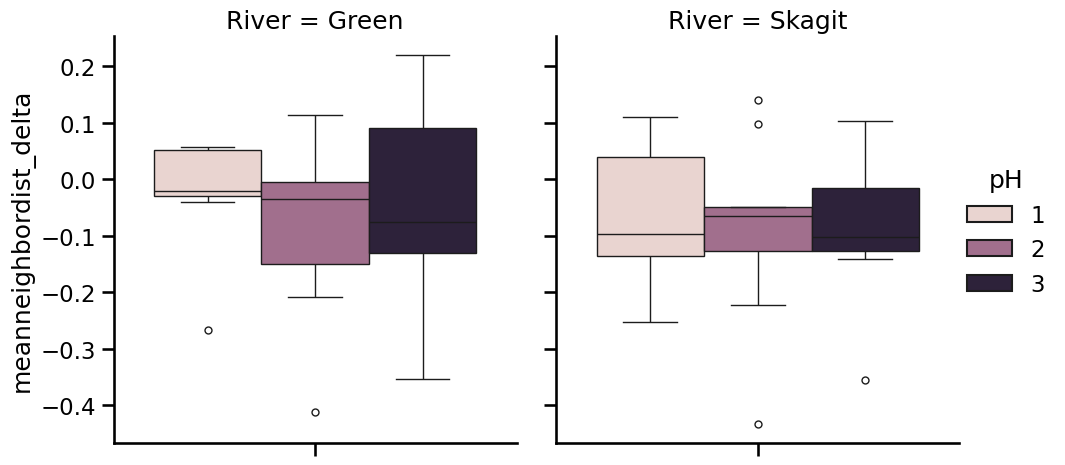

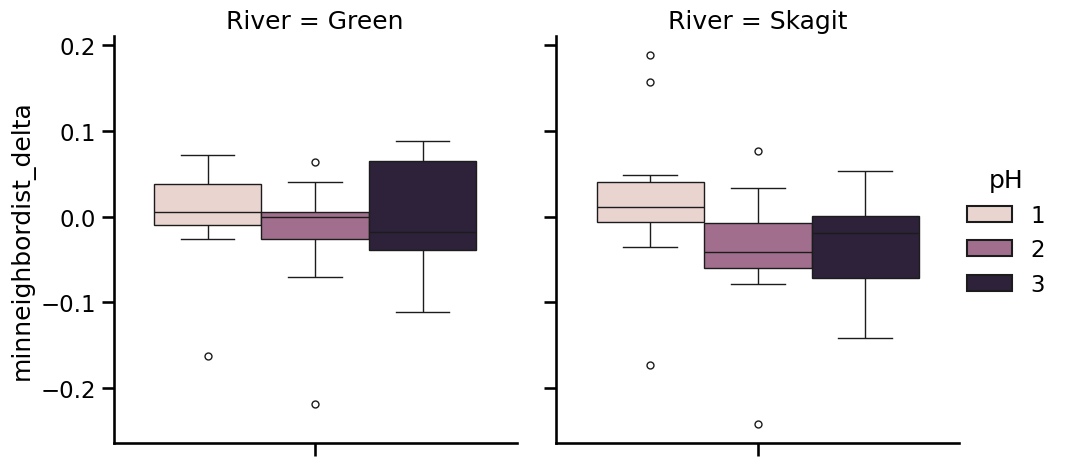

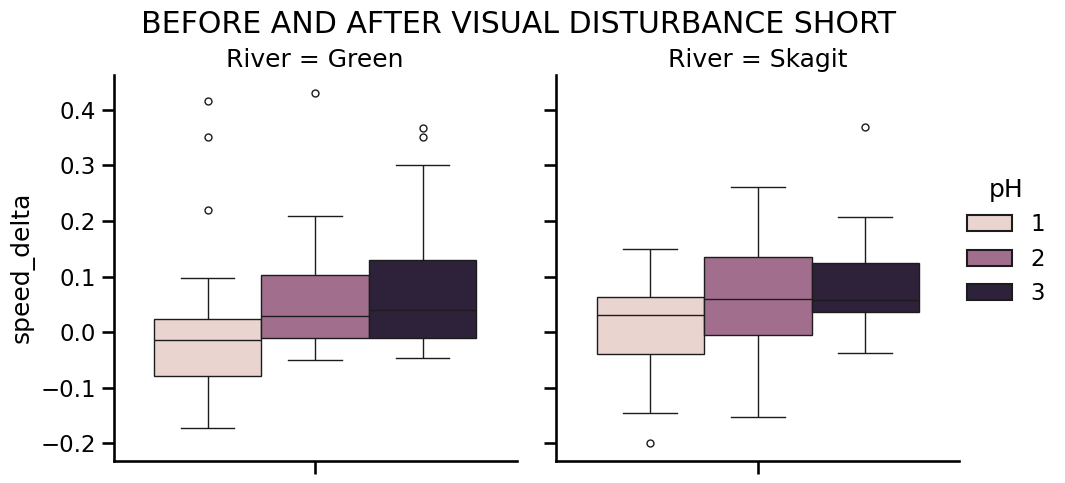

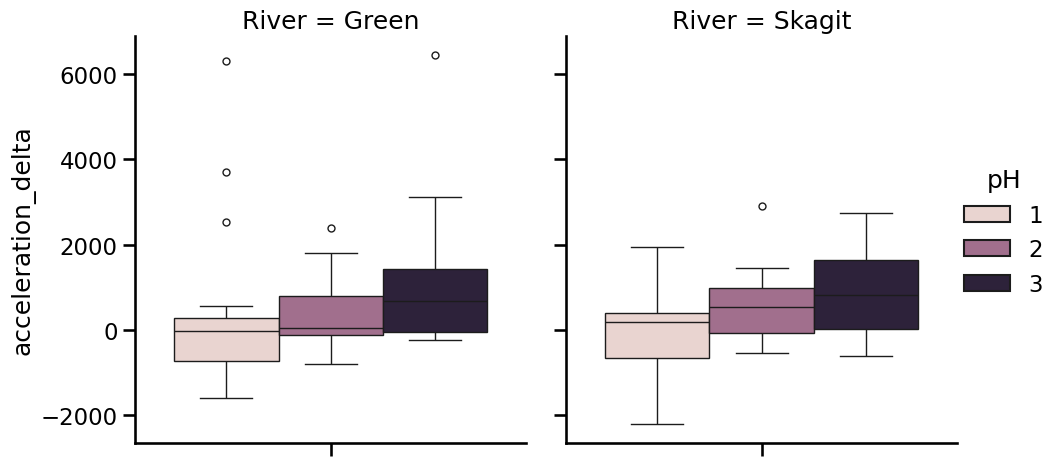

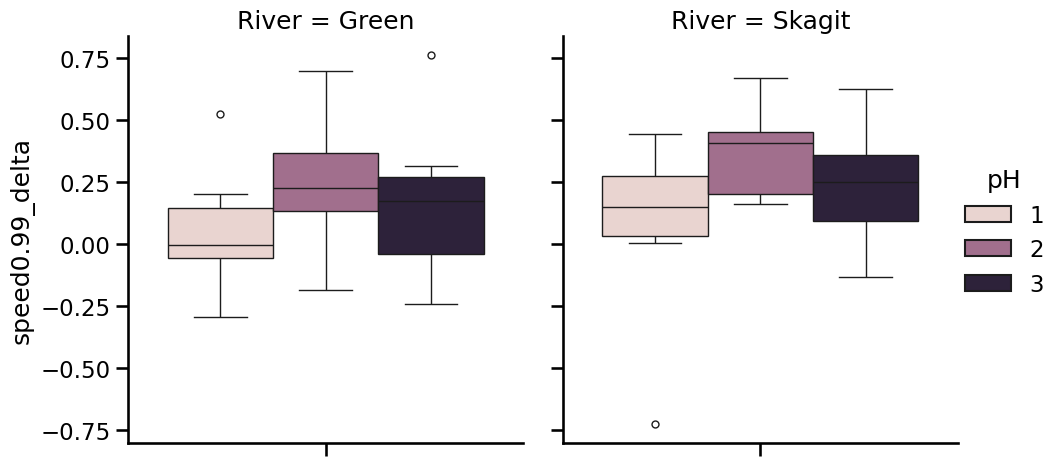

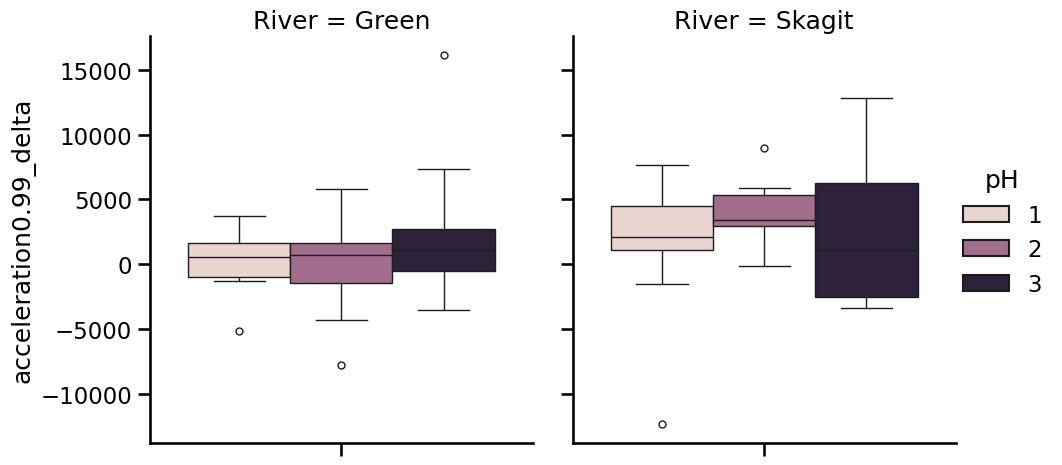

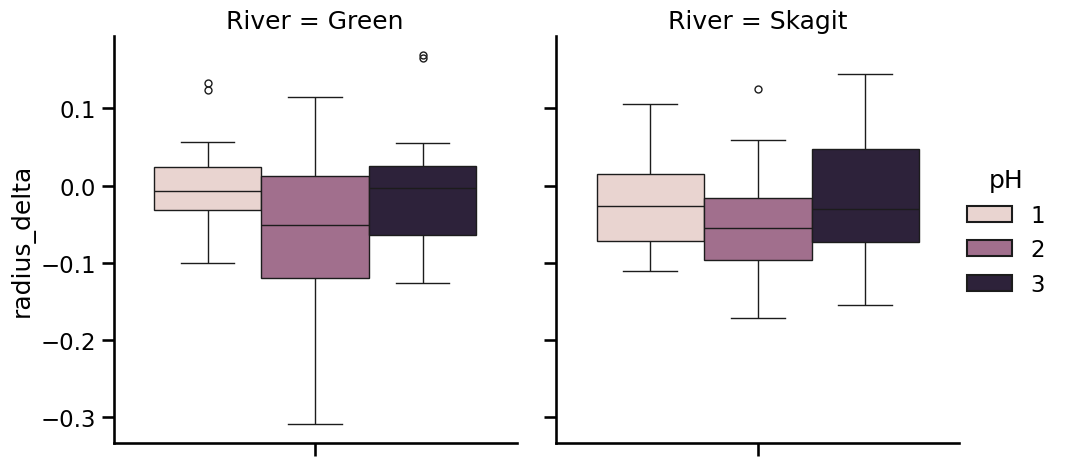

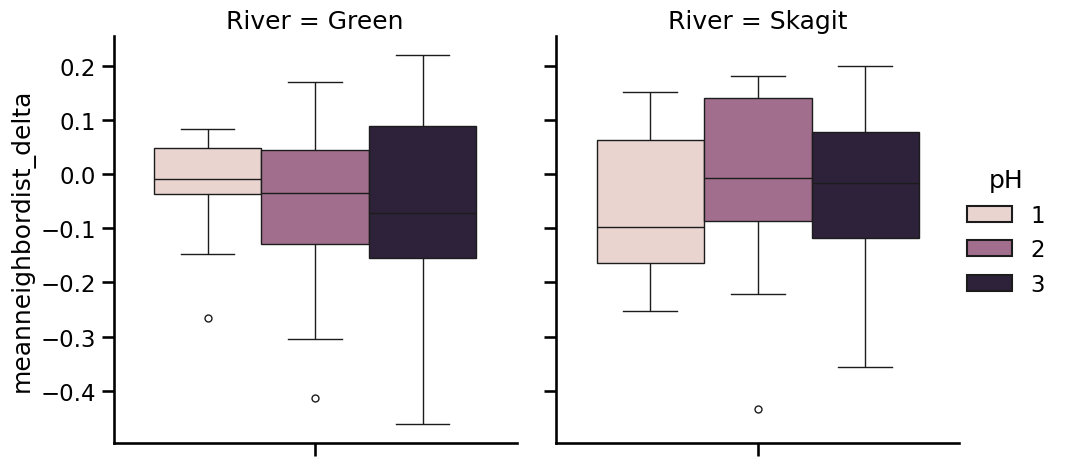

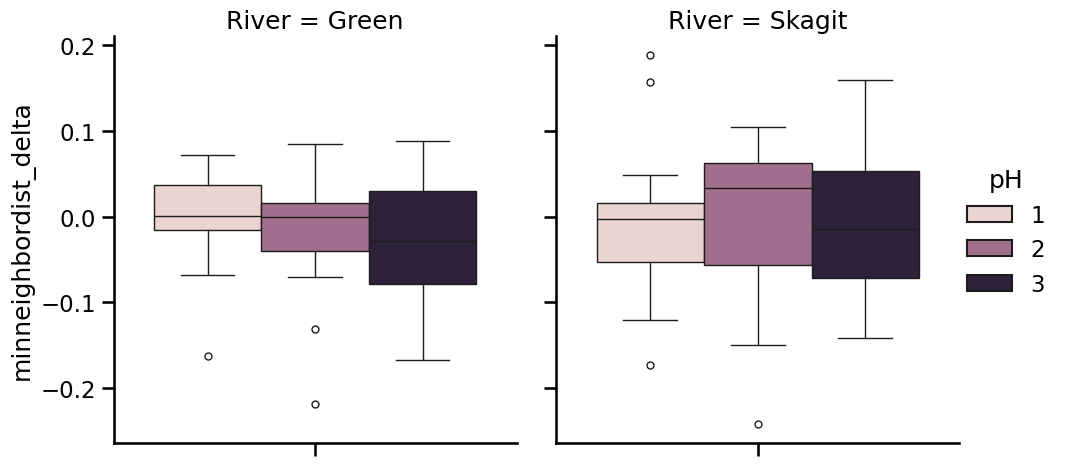

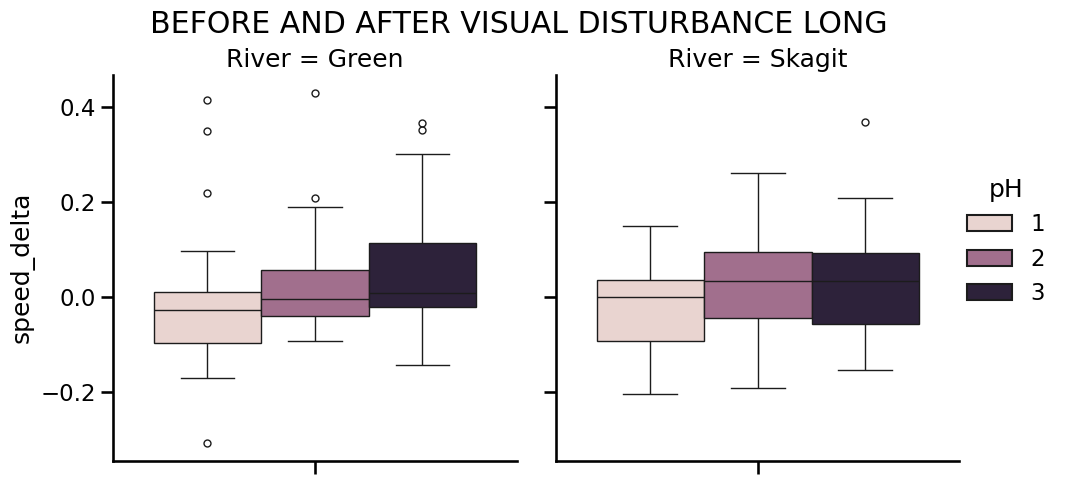

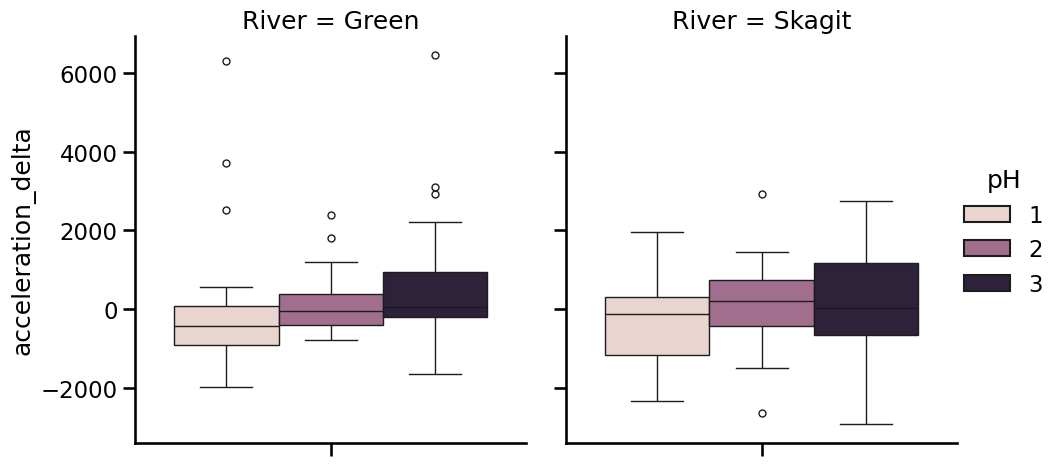

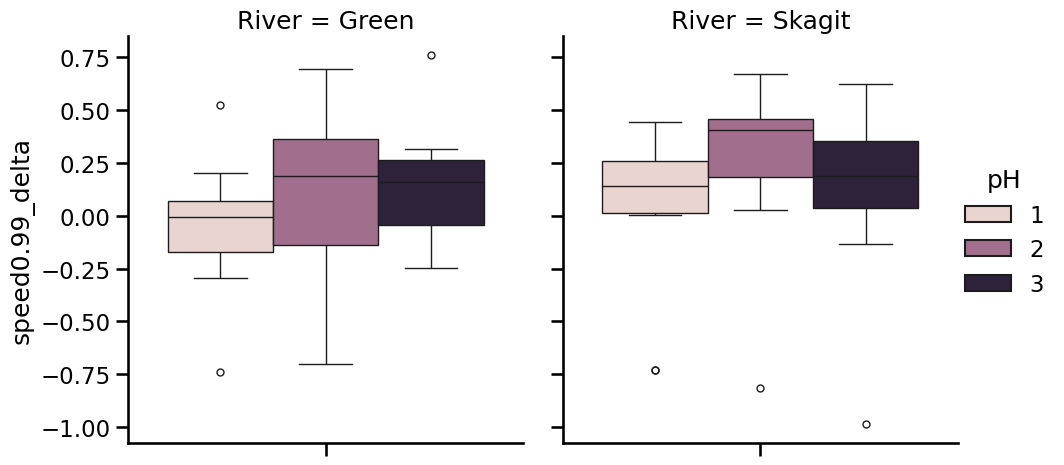

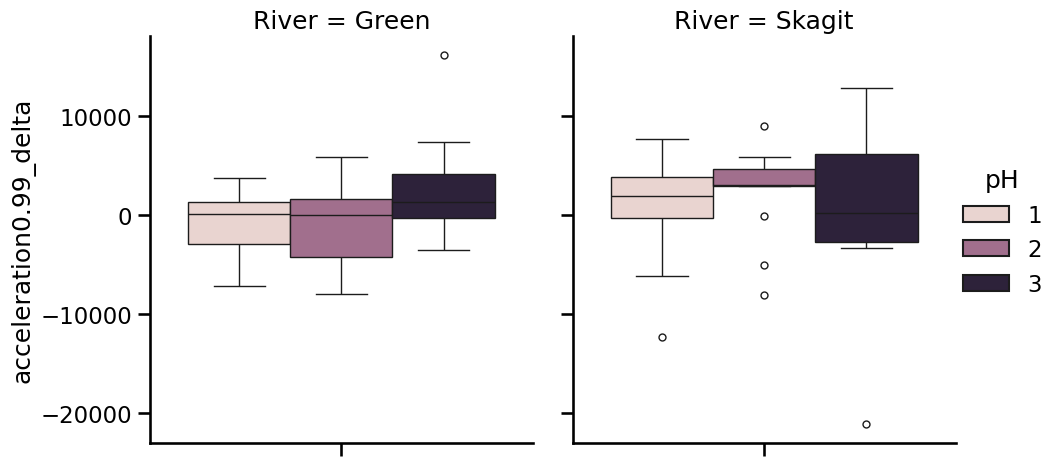

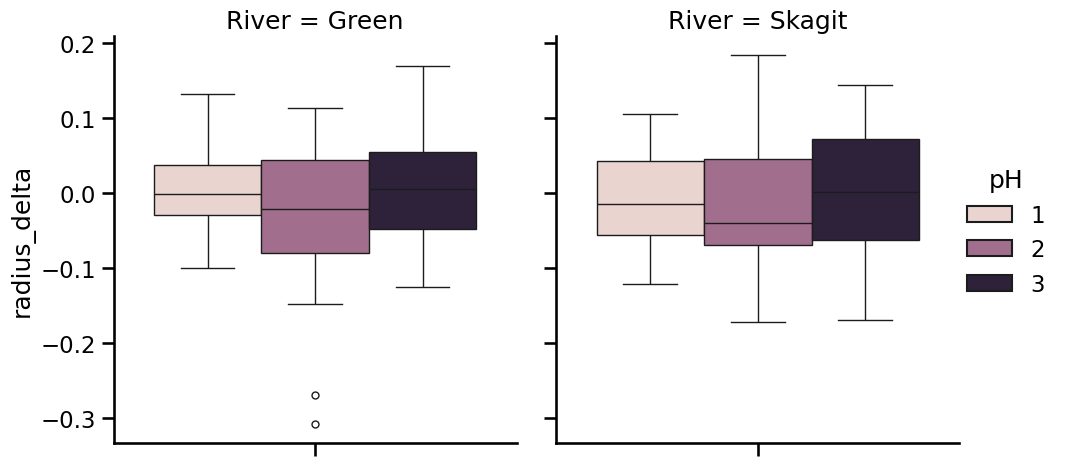

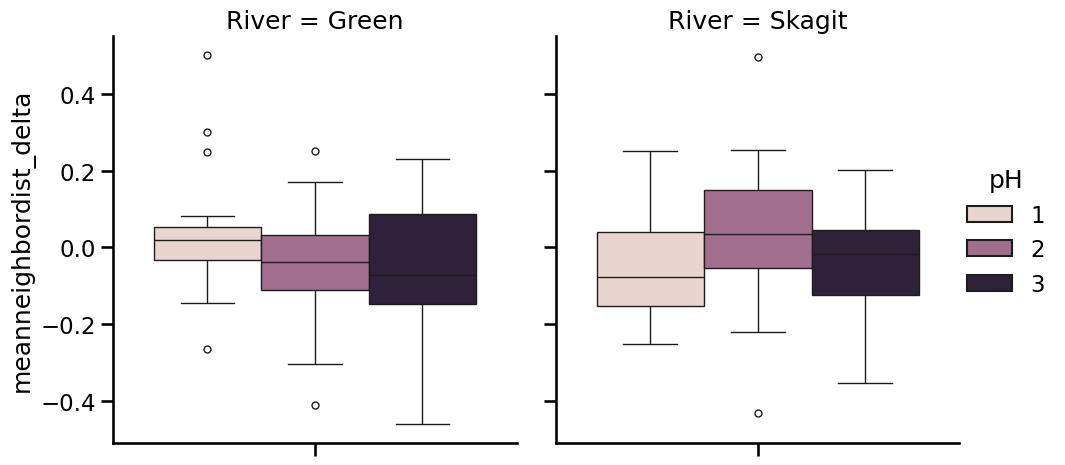

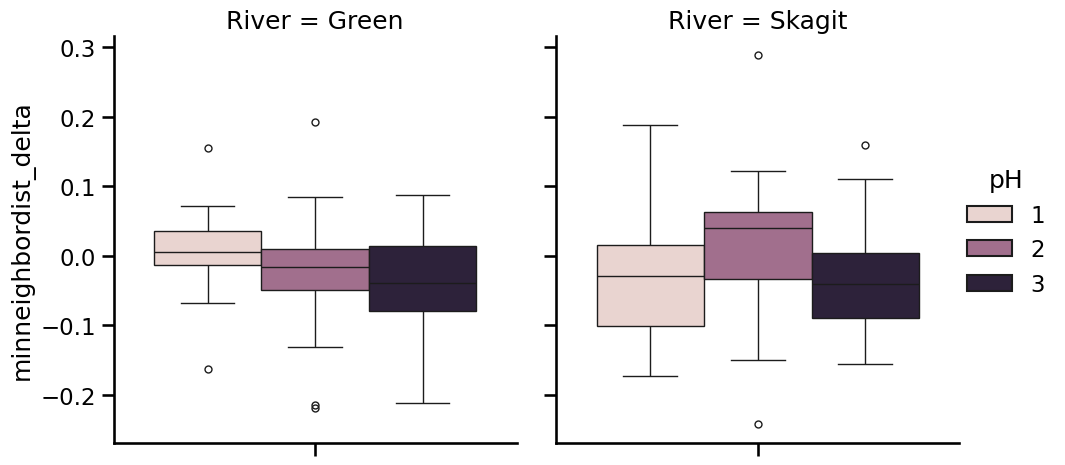

In [18]:
DELTA_VARIABLES = [var + "_delta" for var in DELTA_VARS]

for deltas_df, title in [
    (skin_extract_deltas, "BEFORE AND AFTER SKIN EXTRACT"),
    (visual_disturbance_short_deltas, "BEFORE AND AFTER VISUAL DISTURBANCE SHORT"),
    (visual_disturbance_long_deltas, "BEFORE AND AFTER VISUAL DISTURBANCE LONG"),
]:

    for i, var in enumerate(DELTA_VARIABLES):
        p = sns.catplot(
            data=deltas_df, y=var, col="River", hue="pH",
            # kind="violin",
            kind="box"
            # stat="probability",
            # bins=10,
        )

        # p.set_yscale('log')
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)

